In [2]:
import pandas as pd
import numpy as np

print("========== LOADING USED CAR DATASET ==========")

used_car_df = pd.read_csv("Y:/AI_Vehicle_Service_Repair_Insurance_Intelligence/cleaned/used_car_clean.csv")

print("Dataset loaded successfully!")
print("Shape:", used_car_df.shape)

========== LOADING USED CAR DATASET ==========
Dataset loaded successfully!
Shape: (14984, 18)


In [3]:
print("========== DATASET INSPECTION ==========")

print("\nColumns:")
print(used_car_df.columns.tolist())

print("\nData types:")
print(used_car_df.dtypes)

print("\nMissing values:")
print(used_car_df.isnull().sum())

print("\nDuplicate rows:")
print(used_car_df.duplicated().sum())

print("\nFirst 5 rows:")
display(used_car_df.head())

========== DATASET INSPECTION ==========

Columns:
['Brand', 'model', 'Year', 'Age', 'Engine_Capacity_CC', 'Seating_Capacity', 'Transmission', 'FuelType', 'Owner', 'kmDriven', 'Exterior_Body_Color', 'Interior_Body_Color', 'Has_Insurance', 'Vehicle_Condition_Status', 'PostedDate', 'AdditionInfo', 'AskPrice', 'Overall_Cost']

Data types:
Brand                        object
model                        object
Year                          int64
Age                           int64
Engine_Capacity_CC            int64
Seating_Capacity              int64
Transmission                 object
FuelType                     object
Owner                        object
kmDriven                    float64
Exterior_Body_Color          object
Interior_Body_Color          object
Has_Insurance                object
Vehicle_Condition_Status     object
PostedDate                   object
AdditionInfo                 object
AskPrice                    float64
Overall_Cost                float64
dtype: object


,Brand,model,Year,Age,Engine_Capacity_CC,Seating_Capacity,Transmission,FuelType,Owner,kmDriven,Exterior_Body_Color,Interior_Body_Color,Has_Insurance,Vehicle_Condition_Status,PostedDate,AdditionInfo,AskPrice,Overall_Cost
0,Honda,City,2001,25,1497,5,Manual,Petrol,second,98000.0,Silver,Beige,Yes,Active,2024-11-01,"Honda City v teck in mint condition, valid gen...",195000.0,9800.0
1,Toyota,Innova,2009,17,2494,7,Manual,Diesel,second,190000.0,Black,Beige,Yes,Inactive,2024-07-01,"Toyota Innova 2.5 G (Diesel) 7 Seater, 2009, D...",375000.0,18800.0
2,Volkswagen,VentoTest,2010,16,1198,5,Manual,Diesel,first,77246.0,Black,Grey,Yes,Inactive,2024-11-01,"Volkswagen Vento 2010-2013 Diesel Breeze, 2010...",184999.0,9200.0
3,Maruti Suzuki,Swift,2017,9,1197,5,Manual,Diesel,second,83500.0,Black,Black,Yes,Active,2024-11-01,Maruti Suzuki Swift 2017 Diesel Good Condition,565000.0,25300.0
4,Maruti Suzuki,Baleno,2019,7,1197,5,Automatic,Petrol,first,45000.0,Black,Black,Yes,Inactive,2024-11-01,"Maruti Suzuki Baleno Alpha CVT, 2019, Petrol",685000.0,10300.0


In [4]:
print("========== NUMERICAL SUMMARY ==========")

display(
    used_car_df.describe(include="all").T
)

========== NUMERICAL SUMMARY ==========


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Brand,14984,43,Maruti Suzuki,4610,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,14984,436,Wagon-R,615,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Year,14984.0,NaN,NaN,NaN,2016.342565,4.106331,1978.0,2014.0,2017.0,2019.0,2024.0
Age,14984.0,NaN,NaN,NaN,9.657435,4.106331,2.0,7.0,9.0,12.0,48.0
Engine_Capacity_CC,14984.0,NaN,NaN,NaN,1503.933062,577.264751,796.0,1196.0,1248.0,1798.0,6749.0
Seating_Capacity,14984.0,NaN,NaN,NaN,5.40917,0.981249,4.0,5.0,5.0,5.0,12.0
Transmission,14984,2,Automatic,7808,NaN,NaN,NaN,NaN,NaN,NaN,NaN
FuelType,14984,4,Petrol,6031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Owner,14984,2,second,7790,NaN,NaN,NaN,NaN,NaN,NaN,NaN
kmDriven,14984.0,NaN,NaN,NaN,70947.80586,56728.404965,0.0,45000.0,65500.0,85853.75,980002.0


In [5]:
print("========== TARGET ANALYSIS ==========")

print("Overall Cost statistics:")
display(
    used_car_df["Overall_Cost"].describe()
)

print("\nAsk Price statistics:")
display(
    used_car_df["AskPrice"].describe()
)

print("\nCorrelation:")
display(
    used_car_df[
        [
            "AskPrice",
            "Overall_Cost",
            "Year",
            "Age",
            "Engine_Capacity_CC",
            "Seating_Capacity",
            "kmDriven"
        ]
    ].corr()["Overall_Cost"].sort_values(
        ascending=False
    )
)

========== TARGET ANALYSIS ==========
Overall Cost statistics:


count    14984.000000
mean     14727.829685
std       7692.551011
min        800.000000
25%       8800.000000
50%      13500.000000
75%      19500.000000
max      47600.000000
Name: Overall_Cost, dtype: float64


Ask Price statistics:


count    1.498400e+04
mean     9.973732e+05
std      1.587047e+06
min      1.500000e+04
25%      3.490000e+05
50%      5.700000e+05
75%      1.025000e+06
max      4.250000e+07
Name: AskPrice, dtype: float64


Correlation:


Overall_Cost          1.000000
Engine_Capacity_CC    0.221230
Year                  0.116121
AskPrice              0.092760
Seating_Capacity      0.068194
kmDriven              0.062318
Age                  -0.116121
Name: Overall_Cost, dtype: float64

In [6]:
print("========== COST BY VEHICLE CONDITION ==========")

display(
    used_car_df
    .groupby("Vehicle_Condition_Status")["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
)

========== COST BY VEHICLE CONDITION ==========


,count,mean,median,min,max,std
Vehicle_Condition_Status,,,,,,
Active,12418,14714.768884,13500.0,800.0,47600.0,7662.144522
Inactive,2566,14791.036633,13400.0,800.0,47600.0,7839.243356


In [7]:
print("========== COST BY FUEL TYPE ==========")

display(
    used_car_df
    .groupby("FuelType")["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .sort_values("mean", ascending=False)
)

========== COST BY FUEL TYPE ==========


,count,mean,median,min,max
FuelType,,,,,
Diesel,5126,16711.724542,15300.0,800.0,47600.0
Petrol,6031,14058.912287,13000.0,900.0,47300.0
Hybrid/CNG,1868,13254.710921,12200.0,1500.0,43900.0
Hybrid,1959,13000.714650,12000.0,800.0,37700.0


In [8]:
print("========== OVERALL COST DISTRIBUTION ==========")

print("Skewness:",
      used_car_df["Overall_Cost"].skew())

print("\nCost ranges:")

used_car_df["Cost_Group"] = pd.cut(
    used_car_df["Overall_Cost"],
    bins=[0, 5000, 10000, 15000, 20000, 30000, np.inf],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

display(
    used_car_df["Cost_Group"]
    .value_counts()
    .sort_index()
)

========== OVERALL COST DISTRIBUTION ==========
Skewness: 0.8047605270203532

Cost ranges:


Cost_Group
<=5K       1005
5K-10K     3851
10K-15K    3845
15K-20K    2874
20K-30K    2785
>30K        624
Name: count, dtype: int64

In [9]:
print("========== COST BY TRANSMISSION ==========")

display(
    used_car_df
    .groupby("Transmission")["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

========== COST BY TRANSMISSION ==========


,count,mean,median,min,max,std
Transmission,,,,,,
Automatic,7808,15388.601434,14100.0,800.0,47600.0,8062.539793
Manual,7176,14008.862876,12800.0,800.0,47200.0,7200.611050


In [10]:
print("========== COST BY OWNER ==========")

display(
    used_car_df
    .groupby("Owner")["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max",
        "std"
    ])
    .sort_values("mean", ascending=False)
)

========== COST BY OWNER ==========


,count,mean,median,min,max,std
Owner,,,,,,
first,7194,14904.142341,13800.0,800.0,47600.0,7621.502729
second,7790,14565.006418,13000.0,800.0,47600.0,7754.514468


In [11]:
print("========== COST BY BRAND ==========")

brand_cost = (
    used_car_df
    .groupby("Brand")["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
    .sort_values("mean", ascending=False)
)

display(
    brand_cost.head(20)
)

========== COST BY BRAND ==========


,count,mean,median,min,max
Brand,,,,,
Citroen,2,20600.000000,20600.0,16800.0,24400.0
Rolls-Royce,2,19650.000000,19650.0,11800.0,27500.0
Porsche,33,19603.030303,16800.0,4600.0,35800.0
Ssangyong,5,19260.000000,16600.0,12000.0,27900.0
Jaguar,51,19076.470588,18300.0,5200.0,46200.0
Land Rover,99,18857.575758,17400.0,2600.0,41700.0
Mitsubishi,24,18370.833333,17450.0,4500.0,33200.0
Volvo,66,18362.121212,17100.0,1900.0,39700.0
Audi,364,18078.846154,16250.0,2100.0,47300.0


In [12]:
print("========== ASK PRICE VS OVERALL COST ==========")

print(
    used_car_df[
        ["AskPrice", "Overall_Cost"]
    ].corr()
)

print("\nAverage Overall Cost by Ask Price group:")

used_car_df["AskPrice_Group"] = pd.qcut(
    used_car_df["AskPrice"],
    q=5,
    duplicates="drop"
)

display(
    used_car_df
    .groupby("AskPrice_Group", observed=True)["Overall_Cost"]
    .agg([
        "count",
        "mean",
        "median",
        "min",
        "max"
    ])
)

========== ASK PRICE VS OVERALL COST ==========
              AskPrice  Overall_Cost
AskPrice       1.00000       0.09276
Overall_Cost   0.09276       1.00000

Average Overall Cost by Ask Price group:


,count,mean,median,min,max
AskPrice_Group,,,,,
"(14999.999, 299000.0]",3025,9155.702479,9200.0,800.0,15000.0
"(299000.0, 470000.0]",2979,14804.128902,15900.0,1700.0,23500.0
"(470000.0, 690000.0]",3032,16562.565963,16100.0,1500.0,34500.0
"(690000.0, 1250000.0]",2992,16706.183155,15100.0,1700.0,47600.0
"(1250000.0, 42500000.0]",2956,16468.775372,14900.0,1700.0,47600.0


In [13]:
print("========== OVERALL COST RELATIONSHIP ==========")

numeric_cols = [
    "Year",
    "Age",
    "Engine_Capacity_CC",
    "Seating_Capacity",
    "kmDriven",
    "AskPrice",
    "Overall_Cost"
]

display(
    used_car_df[numeric_cols].corr()["Overall_Cost"]
    .sort_values(ascending=False)
)

========== OVERALL COST RELATIONSHIP ==========


Overall_Cost          1.000000
Engine_Capacity_CC    0.221230
Year                  0.116121
AskPrice              0.092760
Seating_Capacity      0.068194
kmDriven              0.062318
Age                  -0.116121
Name: Overall_Cost, dtype: float64

In [14]:
print("========== ASK PRICE OUTLIERS ==========")

display(
    used_car_df[
        [
            "Brand",
            "model",
            "Year",
            "Age",
            "AskPrice",
            "Overall_Cost"
        ]
    ]
    .sort_values("AskPrice", ascending=False)
    .head(20)
)

========== ASK PRICE OUTLIERS ==========


,Brand,model,Year,Age,AskPrice,Overall_Cost
3329,Rolls-Royce,Phantom Series II,2015,11,42500000.0,27500.0
12679,Lamborghini,Urus,2021,5,39000000.0,6400.0
13280,Mercedes-Benz,G Class,2023,3,34800000.0,10800.0
10288,Mercedes-Benz,G Class,2024,2,30500000.0,13200.0
962,Lexus,LX,2024,2,27750000.0,10600.0
331,Aston Martin,Vanquish,2016,10,26400000.0,5000.0
811,Mercedes-Benz,G Class,2019,7,26000000.0,1900.0
5765,Mercedes-Benz,G Class,2019,7,24900000.0,23000.0
1187,Toyota,Land Cruiser,2023,3,24700000.0,12100.0
7432,Mercedes-Benz,SL-Class,2024,2,24500000.0,14200.0


In [15]:
print("========== ASK PRICE / OVERALL COST RATIO ==========")

used_car_df["Cost_to_Ask_Ratio"] = (
    used_car_df["Overall_Cost"] /
    used_car_df["AskPrice"]
)

display(
    used_car_df["Cost_to_Ask_Ratio"].describe()
)

print("\nHighest ratios:")

display(
    used_car_df[
        [
            "Brand",
            "model",
            "Year",
            "AskPrice",
            "Overall_Cost",
            "Cost_to_Ask_Ratio"
        ]
    ]
    .sort_values(
        "Cost_to_Ask_Ratio",
        ascending=False
    )
    .head(20)
)

========== ASK PRICE / OVERALL COST RATIO ==========


count    14984.000000
mean         0.028349
std          0.017464
min          0.000073
25%          0.012061
50%          0.026491
75%          0.049796
max          0.053333
Name: Cost_to_Ask_Ratio, dtype: float64


Highest ratios:


,Brand,model,Year,AskPrice,Overall_Cost,Cost_to_Ask_Ratio
1751,Mahindra,Marshal,2000,15000.0,800.0,0.053333
14434,Renault,Duster,2013,15000.0,800.0,0.053333
13579,BMW,5 Series,2014,15000.0,800.0,0.053333
10349,Maruti Suzuki,Brezza,2023,15000.0,800.0,0.053333
7240,Maruti Suzuki,Zen-Estilo,1998,27000.0,1400.0,0.051852
6358,Maruti Suzuki,800,1994,35000.0,1800.0,0.051429
7952,Hyundai,i10,2009,35000.0,1800.0,0.051429
13797,Maruti Suzuki,800,2005,35000.0,1800.0,0.051429
9192,Maruti Suzuki,Fronx,2000,47000.0,2400.0,0.051064
3416,Honda,City,2001,55000.0,2800.0,0.050909


In [16]:
print("========== USED CAR DATA CLEANING & FEATURE ENGINEERING ==========")

========== USED CAR DATA CLEANING & FEATURE ENGINEERING ==========


In [17]:
print("========== CATEGORICAL VALUE CHECK ==========")

categorical_cols = [
    "Brand",
    "model",
    "Transmission",
    "FuelType",
    "Owner",
    "Exterior_Body_Color",
    "Interior_Body_Color",
    "Has_Insurance",
    "Vehicle_Condition_Status"
]

for col in categorical_cols:
    print(f"\n--- {col} ---")
    print("Unique values:", used_car_df[col].nunique())
    print(used_car_df[col].value_counts().head(20))

========== CATEGORICAL VALUE CHECK ==========

--- Brand ---
Unique values: 43
Brand
Maruti Suzuki    4610
Hyundai          2466
Honda            1291
Toyota           1116
Mahindra          744
Mercedes-Benz     614
Tata              599
Volkswagen        494
BMW               471
Ford              390
Renault           376
Audi              364
Skoda             282
Kia               225
Chevrolet         130
Nissan            117
MG                112
Jeep              102
Land Rover         99
Volvo              66
Name: count, dtype: int64

--- model ---
Unique values: 436
model
Wagon-R          615
City             551
Ertiga           440
Swift            412
Swift-Dzire      384
Creta            367
Celerio          330
i10              311
Grand i10        299
Eeco             286
Baleno           280
i20              245
Innova Crysta    236
Verna            235
Fortuner         232
Amaze            221
Polo             217
Alto-800         197
XUV500           193
KWID      

In [18]:
print("========== NUMERICAL VALIDITY CHECK ==========")

numeric_check_cols = [
    "Year",
    "Age",
    "Engine_Capacity_CC",
    "Seating_Capacity",
    "kmDriven",
    "AskPrice",
    "Overall_Cost"
]

for col in numeric_check_cols:
    print(f"\n--- {col} ---")
    print("Min :", used_car_df[col].min())
    print("Max :", used_car_df[col].max())
    print("Negative values:", (used_car_df[col] < 0).sum())

========== NUMERICAL VALIDITY CHECK ==========

--- Year ---
Min : 1978
Max : 2024
Negative values: 0

--- Age ---
Min : 2
Max : 48
Negative values: 0

--- Engine_Capacity_CC ---
Min : 796
Max : 6749
Negative values: 0

--- Seating_Capacity ---
Min : 4
Max : 12
Negative values: 0

--- kmDriven ---
Min : 0.0
Max : 980002.0
Negative values: 0

--- AskPrice ---
Min : 15000.0
Max : 42500000.0
Negative values: 0

--- Overall_Cost ---
Min : 800.0
Max : 47600.0
Negative values: 0


In [19]:
print("========== YEAR vs AGE CONSISTENCY ==========")

current_year = 2024

used_car_df["Calculated_Age"] = (
    current_year - used_car_df["Year"]
)

used_car_df["Age_Difference"] = (
    used_car_df["Age"] - used_car_df["Calculated_Age"]
)

print(
    "Age difference value counts:"
)

display(
    used_car_df["Age_Difference"]
    .value_counts()
    .sort_index()
)

========== YEAR vs AGE CONSISTENCY ==========
Age difference value counts:


Age_Difference
2    14984
Name: count, dtype: int64

In [20]:
print("========== OUTLIER CHECK ==========")

outlier_cols = [
    "Engine_Capacity_CC",
    "kmDriven",
    "AskPrice",
    "Overall_Cost"
]

for col in outlier_cols:

    Q1 = used_car_df[col].quantile(0.25)
    Q3 = used_car_df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = used_car_df[
        (used_car_df[col] < lower_bound) |
        (used_car_df[col] > upper_bound)
    ]

    print(f"\n--- {col} ---")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower bound:", lower_bound)
    print("Upper bound:", upper_bound)
    print("Outlier count:", len(outliers))
    print(
        "Outlier percentage:",
        round(len(outliers) / len(used_car_df) * 100, 2),
        "%"
    )

========== OUTLIER CHECK ==========

--- Engine_Capacity_CC ---
Q1: 1196.0
Q3: 1798.0
IQR: 602.0
Lower bound: 293.0
Upper bound: 2701.0
Outlier count: 1011
Outlier percentage: 6.75 %

--- kmDriven ---
Q1: 45000.0
Q3: 85853.75
IQR: 40853.75
Lower bound: -16280.625
Upper bound: 147134.375
Outlier count: 630
Outlier percentage: 4.2 %

--- AskPrice ---
Q1: 349000.0
Q3: 1025000.0
IQR: 676000.0
Lower bound: -665000.0
Upper bound: 2039000.0
Outlier count: 1447
Outlier percentage: 9.66 %

--- Overall_Cost ---
Q1: 8800.0
Q3: 19500.0
IQR: 10700.0
Lower bound: -7250.0
Upper bound: 35550.0
Outlier count: 201
Outlier percentage: 1.34 %


In [21]:
print("========== HIGH KM DRIVEN VEHICLES ==========")

display(
    used_car_df[
        [
            "Brand",
            "model",
            "Year",
            "Age",
            "kmDriven",
            "AskPrice",
            "Overall_Cost"
        ]
    ]
    .sort_values("kmDriven", ascending=False)
    .head(20)
)

========== HIGH KM DRIVEN VEHICLES ==========


,Brand,model,Year,Age,kmDriven,AskPrice,Overall_Cost
6676,Volkswagen,Polo,2019,7,980002.0,675000.0,26600.0
4766,Maruti Suzuki,Alto-800,2019,7,980000.0,310000.0,15500.0
7735,Chevrolet,Cruze,2012,14,950000.0,350000.0,17500.0
14902,Honda,Amaze,2018,8,950000.0,320000.0,16000.0
13257,Hyundai,Accent,2011,15,950000.0,140000.0,7000.0
11444,Maruti Suzuki,Swift-Dzire-Tour,2022,4,901500.0,690000.0,17800.0
13108,Maruti Suzuki,Eeco,2019,7,900000.0,345000.0,17200.0
3265,Mitsubishi,Pajero Sport,2015,11,850000.0,875000.0,26700.0
9408,Honda,Amaze,2013,13,850000.0,450000.0,22500.0
2221,Mercedes-Benz,GLE Class,2016,10,850000.0,2600000.0,14300.0


In [22]:
print("========== ENGINE CAPACITY EXTREMES ==========")

display(
    used_car_df[
        [
            "Brand",
            "model",
            "Year",
            "Engine_Capacity_CC",
            "Seating_Capacity",
            "AskPrice",
            "Overall_Cost"
        ]
    ]
    .sort_values(
        "Engine_Capacity_CC",
        ascending=False
    )
    .head(20)
)

========== ENGINE CAPACITY EXTREMES ==========


,Brand,model,Year,Engine_Capacity_CC,Seating_Capacity,AskPrice,Overall_Cost
4943,Rolls-Royce,Phantom Drop HeadCoupe,2019,6749,4,235000.0,11800.0
8475,Porsche,Panamera,2020,6749,4,15000000.0,32600.0
7612,Bentley,Flying Spur,2017,6749,4,18500000.0,6700.0
3329,Rolls-Royce,Phantom Series II,2015,6749,4,42500000.0,27500.0
331,Aston Martin,Vanquish,2016,6749,4,26400000.0,5000.0
9546,Maserati,Gran Turismo,2017,6749,4,8000000.0,8700.0
5138,Porsche,Panamera,2017,6749,4,6900000.0,35700.0
12679,Lamborghini,Urus,2021,6749,4,39000000.0,6400.0
8601,Audi,2.9 Sportback,2018,3996,5,7500000.0,17700.0
11768,Mercedes-Benz,S-Class,2019,3982,5,8900000.0,29500.0


In [23]:
print("========== POSTED DATE ANALYSIS ==========")

print("Data type before conversion:")
print(used_car_df["PostedDate"].dtype)

print("\nUnique Posted Dates:")
print(used_car_df["PostedDate"].nunique())

print("\nPosted Date distribution:")
print(
    used_car_df["PostedDate"]
    .value_counts()
    .sort_index()
)

========== POSTED DATE ANALYSIS ==========
Data type before conversion:
object

Unique Posted Dates:
13

Posted Date distribution:
PostedDate
2023-12-01        3
2024-01-01        2
2024-02-01        2
2024-03-01        1
2024-04-01        8
2024-05-01        6
2024-06-01       21
2024-07-01       32
2024-08-01       76
2024-09-01      171
2024-10-01      655
2024-11-01    13244
2024-12-01      763
Name: count, dtype: int64


In [24]:
print("========== CONVERTING POSTED DATE ==========")

used_car_df["PostedDate"] = pd.to_datetime(
    used_car_df["PostedDate"],
    errors="coerce"
)

print("Data type after conversion:")
print(used_car_df["PostedDate"].dtype)

print("\nMissing dates after conversion:")
print(used_car_df["PostedDate"].isnull().sum())

print("\nDate range:")
print("Minimum:", used_car_df["PostedDate"].min())
print("Maximum:", used_car_df["PostedDate"].max())

========== CONVERTING POSTED DATE ==========
Data type after conversion:
datetime64[ns]

Missing dates after conversion:
0

Date range:
Minimum: 2023-12-01 00:00:00
Maximum: 2024-12-01 00:00:00


In [25]:
print("========== CREATING DATE FEATURES ==========")

used_car_df["Posted_Year"] = (
    used_car_df["PostedDate"].dt.year
)

used_car_df["Posted_Month"] = (
    used_car_df["PostedDate"].dt.month
)

used_car_df["Posted_Quarter"] = (
    used_car_df["PostedDate"].dt.quarter
)

used_car_df["Posted_Weekday"] = (
    used_car_df["PostedDate"].dt.weekday
)

used_car_df["Posted_Is_Weekend"] = (
    used_car_df["Posted_Weekday"] >= 5
).astype(int)

print("Date features created successfully!")

display(
    used_car_df[
        [
            "PostedDate",
            "Posted_Year",
            "Posted_Month",
            "Posted_Quarter",
            "Posted_Weekday",
            "Posted_Is_Weekend"
        ]
    ].head(10)
)

========== CREATING DATE FEATURES ==========
Date features created successfully!


,PostedDate,Posted_Year,Posted_Month,Posted_Quarter,Posted_Weekday,Posted_Is_Weekend
0,2024-11-01,2024,11,4,4,0
1,2024-07-01,2024,7,3,0,0
2,2024-11-01,2024,11,4,4,0
3,2024-11-01,2024,11,4,4,0
4,2024-11-01,2024,11,4,4,0
5,2024-11-01,2024,11,4,4,0
6,2024-11-01,2024,11,4,4,0
7,2024-11-01,2024,11,4,4,0
8,2024-11-01,2024,11,4,4,0
9,2024-11-01,2024,11,4,4,0


In [26]:
print("========== FEATURE SELECTION ==========")

# Target variable
target = "Overall_Cost"

# Features selected for Machine Learning
selected_features = [
    "Brand",
    "model",
    "Year",
    "Age",
    "Engine_Capacity_CC",
    "Seating_Capacity",
    "Transmission",
    "FuelType",
    "Owner",
    "kmDriven",
    "Exterior_Body_Color",
    "Interior_Body_Color",
    "Has_Insurance",
    "Vehicle_Condition_Status",
    "AskPrice",
    "Posted_Year",
    "Posted_Month",
    "Posted_Quarter",
    "Posted_Weekday",
    "Posted_Is_Weekend"
]

print("Number of selected features:", len(selected_features))

print("\nSelected features:")
for i, feature in enumerate(selected_features, 1):
    print(i, ".", feature)

print("\nTarget variable:")
print(target)

========== FEATURE SELECTION ==========
Number of selected features: 20

Selected features:
1 . Brand
2 . model
3 . Year
4 . Age
5 . Engine_Capacity_CC
6 . Seating_Capacity
7 . Transmission
8 . FuelType
9 . Owner
10 . kmDriven
11 . Exterior_Body_Color
12 . Interior_Body_Color
13 . Has_Insurance
14 . Vehicle_Condition_Status
15 . AskPrice
16 . Posted_Year
17 . Posted_Month
18 . Posted_Quarter
19 . Posted_Weekday
20 . Posted_Is_Weekend

Target variable:
Overall_Cost


In [27]:
print("========== CREATING ML DATASET ==========")

X_used_car = used_car_df[selected_features].copy()
y_used_car = used_car_df[target].copy()

print("X shape:", X_used_car.shape)
print("y shape:", y_used_car.shape)

print("\nX columns:")
print(X_used_car.columns.tolist())

print("\nTarget statistics:")
print(y_used_car.describe())

========== CREATING ML DATASET ==========
X shape: (14984, 20)
y shape: (14984,)

X columns:
['Brand', 'model', 'Year', 'Age', 'Engine_Capacity_CC', 'Seating_Capacity', 'Transmission', 'FuelType', 'Owner', 'kmDriven', 'Exterior_Body_Color', 'Interior_Body_Color', 'Has_Insurance', 'Vehicle_Condition_Status', 'AskPrice', 'Posted_Year', 'Posted_Month', 'Posted_Quarter', 'Posted_Weekday', 'Posted_Is_Weekend']

Target statistics:
count    14984.000000
mean     14727.829685
std       7692.551011
min        800.000000
25%       8800.000000
50%      13500.000000
75%      19500.000000
max      47600.000000
Name: Overall_Cost, dtype: float64


In [28]:
print("========== FINAL FEATURE VALIDATION ==========")

print("Missing values in X:")
display(X_used_car.isnull().sum())

print("\nMissing values in y:")
print(y_used_car.isnull().sum())

print("\nDuplicate rows in X:")
print(X_used_car.duplicated().sum())

print("\nData types:")
display(X_used_car.dtypes)

========== FINAL FEATURE VALIDATION ==========
Missing values in X:


Brand                       0
model                       0
Year                        0
Age                         0
Engine_Capacity_CC          0
Seating_Capacity            0
Transmission                0
FuelType                    0
Owner                       0
kmDriven                    0
Exterior_Body_Color         0
Interior_Body_Color         0
Has_Insurance               0
Vehicle_Condition_Status    0
AskPrice                    0
Posted_Year                 0
Posted_Month                0
Posted_Quarter              0
Posted_Weekday              0
Posted_Is_Weekend           0
dtype: int64


Missing values in y:
0

Duplicate rows in X:
80

Data types:


Brand                        object
model                        object
Year                          int64
Age                           int64
Engine_Capacity_CC            int64
Seating_Capacity              int64
Transmission                 object
FuelType                     object
Owner                        object
kmDriven                    float64
Exterior_Body_Color          object
Interior_Body_Color          object
Has_Insurance                object
Vehicle_Condition_Status     object
AskPrice                    float64
Posted_Year                   int32
Posted_Month                  int32
Posted_Quarter                int32
Posted_Weekday                int32
Posted_Is_Weekend             int64
dtype: object

In [29]:
print("========== TRAIN TEST SPLIT ==========")

from sklearn.model_selection import train_test_split

X_train_used, X_test_used, y_train_used, y_test_used = train_test_split(
    X_used_car,
    y_used_car,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train_used.shape)
print("y_train:", y_train_used.shape)

print("\nTesting data:")
print("X_test :", X_test_used.shape)
print("y_test :", y_test_used.shape)

========== TRAIN TEST SPLIT ==========
Training data:
X_train: (11987, 20)
y_train: (11987,)

Testing data:
X_test : (2997, 20)
y_test : (2997,)


In [30]:
print("========== TRAIN TEST VALIDATION ==========")

print("Training target statistics:")
display(y_train_used.describe())

print("\nTesting target statistics:")
display(y_test_used.describe())

print("\nTraining target mean:", round(y_train_used.mean(), 2))
print("Testing target mean :", round(y_test_used.mean(), 2))

========== TRAIN TEST VALIDATION ==========
Training target statistics:


count    11987.000000
mean     14730.374572
std       7709.977968
min        800.000000
25%       8800.000000
50%      13400.000000
75%      19500.000000
max      47600.000000
Name: Overall_Cost, dtype: float64


Testing target statistics:


count     2997.000000
mean     14717.650984
std       7623.720017
min       1700.000000
25%       8800.000000
50%      13600.000000
75%      19400.000000
max      46200.000000
Name: Overall_Cost, dtype: float64


Training target mean: 14730.37
Testing target mean : 14717.65


In [31]:
print("========== DEFINING PREPROCESSING FEATURES ==========")

numerical_features_used = [
    "Year",
    "Age",
    "Engine_Capacity_CC",
    "Seating_Capacity",
    "kmDriven",
    "AskPrice",
    "Posted_Year",
    "Posted_Month",
    "Posted_Quarter",
    "Posted_Weekday",
    "Posted_Is_Weekend"
]

categorical_features_used = [
    "Brand",
    "model",
    "Transmission",
    "FuelType",
    "Owner",
    "Exterior_Body_Color",
    "Interior_Body_Color",
    "Has_Insurance",
    "Vehicle_Condition_Status"
]

print("Numerical features:", len(numerical_features_used))
print("Categorical features:", len(categorical_features_used))

print("\nNumerical features:")
print(numerical_features_used)

print("\nCategorical features:")
print(categorical_features_used)

========== DEFINING PREPROCESSING FEATURES ==========
Numerical features: 11
Categorical features: 9

Numerical features:
['Year', 'Age', 'Engine_Capacity_CC', 'Seating_Capacity', 'kmDriven', 'AskPrice', 'Posted_Year', 'Posted_Month', 'Posted_Quarter', 'Posted_Weekday', 'Posted_Is_Weekend']

Categorical features:
['Brand', 'model', 'Transmission', 'FuelType', 'Owner', 'Exterior_Body_Color', 'Interior_Body_Color', 'Has_Insurance', 'Vehicle_Condition_Status']


In [32]:
print("========== CREATING PREPROCESSING PIPELINE ==========")

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numeric_pipeline_used = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

# Categorical preprocessing
categorical_pipeline_used = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

# Combined preprocessor
preprocessor_used = ColumnTransformer([
    (
        "num",
        numeric_pipeline_used,
        numerical_features_used
    ),
    (
        "cat",
        categorical_pipeline_used,
        categorical_features_used
    )
])

print("Preprocessing pipeline created successfully!")

========== CREATING PREPROCESSING PIPELINE ==========
Preprocessing pipeline created successfully!


In [33]:
print("========== FITTING PREPROCESSOR ==========")

X_train_used_processed = preprocessor_used.fit_transform(
    X_train_used
)

print(
    "Processed training shape:",
    X_train_used_processed.shape
)

========== FITTING PREPROCESSOR ==========
Processed training shape: (11987, 496)


In [34]:
print("========== TRANSFORMING TEST DATA ==========")

X_test_used_processed = preprocessor_used.transform(
    X_test_used
)

print(
    "Processed testing shape:",
    X_test_used_processed.shape
)

========== TRANSFORMING TEST DATA ==========
Processed testing shape: (2997, 496)


In [35]:
print("========== PREPROCESSING VALIDATION ==========")

print("Original training features :", X_train_used.shape[1])
print("Processed training features:", X_train_used_processed.shape[1])

print("Original testing features  :", X_test_used.shape[1])
print("Processed testing features :", X_test_used_processed.shape[1])

print("\nTraining samples:", X_train_used_processed.shape[0])
print("Testing samples :", X_test_used_processed.shape[0])

========== PREPROCESSING VALIDATION ==========
Original training features : 20
Processed training features: 496
Original testing features  : 20
Processed testing features : 496

Training samples: 11987
Testing samples : 2997


In [36]:
print("========== TRAINING RIDGE REGRESSION ==========")

from sklearn.linear_model import Ridge
import time

ridge_used = Ridge(alpha=1.0)

start_time = time.time()

ridge_used.fit(
    X_train_used_processed,
    y_train_used
)

training_time_ridge_used = time.time() - start_time

print(
    "Training completed successfully!"
)

print(
    "Training time:",
    round(training_time_ridge_used, 2),
    "seconds"
)

========== TRAINING RIDGE REGRESSION ==========
Training completed successfully!
Training time: 0.01 seconds


In [37]:
print("========== RIDGE PREDICTIONS ==========")

y_pred_ridge_used = ridge_used.predict(
    X_test_used_processed
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_ridge_used[:10])

========== RIDGE PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[15267.2917886  12708.99150708 13553.06930527 13376.22295918
 16029.94031413 12985.22064276 13350.96120252 18038.42619945
 14638.01811775 14171.62583637]


In [38]:
print("========== RIDGE MODEL EVALUATION ==========")

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
import numpy as np

mae_ridge_used = mean_absolute_error(
    y_test_used,
    y_pred_ridge_used
)

rmse_ridge_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_ridge_used
    )
)

r2_ridge_used = r2_score(
    y_test_used,
    y_pred_ridge_used
)

print("MAE :", round(mae_ridge_used, 4))
print("RMSE:", round(rmse_ridge_used, 4))
print("R²  :", round(r2_ridge_used, 4))

========== RIDGE MODEL EVALUATION ==========
MAE : 5984.6004
RMSE: 7394.59
R²  : 0.0589


In [39]:
print("========== ACTUAL VS PREDICTED ==========")

ridge_results_used = pd.DataFrame({
    "Actual Cost": y_test_used.values,
    "Predicted Cost": y_pred_ridge_used
})

ridge_results_used["Error"] = (
    ridge_results_used["Actual Cost"]
    - ridge_results_used["Predicted Cost"]
)

ridge_results_used["Absolute Error"] = (
    ridge_results_used["Error"].abs()
)

ridge_results_used["Percentage Error"] = (
    ridge_results_used["Absolute Error"]
    / ridge_results_used["Actual Cost"]
) * 100

display(
    ridge_results_used.head(20)
)

========== ACTUAL VS PREDICTED ==========


,Actual Cost,Predicted Cost,Error,Absolute Error,Percentage Error
0,20300.0,15267.291789,5032.708211,5032.708211,24.791666
1,14000.0,12708.991507,1291.008493,1291.008493,9.221489
2,18600.0,13553.069305,5046.930695,5046.930695,27.134036
3,7500.0,13376.222959,-5876.222959,5876.222959,78.349639
4,21600.0,16029.940314,5570.059686,5570.059686,25.787313
5,5200.0,12985.220643,-7785.220643,7785.220643,149.715782
6,14000.0,13350.961203,649.038797,649.038797,4.635991
7,5700.0,18038.426199,-12338.426199,12338.426199,216.463618
8,15100.0,14638.018118,461.981882,461.981882,3.059483
9,21500.0,14171.625836,7328.374164,7328.374164,34.085461


In [40]:
print("========== TRAINING RANDOM FOREST ==========")

from sklearn.ensemble import RandomForestRegressor
import time

rf_used = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_used.fit(
    X_train_used_processed,
    y_train_used
)

training_time_rf_used = time.time() - start_time

print("Training completed successfully!")

print(
    "Training time:",
    round(training_time_rf_used, 2),
    "seconds"
)

========== TRAINING RANDOM FOREST ==========
Training completed successfully!
Training time: 44.61 seconds


In [41]:
print("========== RANDOM FOREST PREDICTIONS ==========")

y_pred_rf_used = rf_used.predict(
    X_test_used_processed
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_rf_used[:10])

========== RANDOM FOREST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[15226.75       12978.08333333 19350.          7486.5
 19932.11666667 14885.5        11776.5        14453.5
 16396.         17133.        ]


In [42]:
print("========== RANDOM FOREST EVALUATION ==========")

mae_rf_used = mean_absolute_error(
    y_test_used,
    y_pred_rf_used
)

rmse_rf_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_rf_used
    )
)

r2_rf_used = r2_score(
    y_test_used,
    y_pred_rf_used
)

print("MAE :", round(mae_rf_used, 4))
print("RMSE:", round(rmse_rf_used, 4))
print("R²  :", round(r2_rf_used, 4))

========== RANDOM FOREST EVALUATION ==========
MAE : 5261.1952
RMSE: 6989.6646
R²  : 0.1591


In [43]:
print("========== MODEL COMPARISON ==========")

model_comparison_used = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest"
    ],
    "MAE": [
        mae_ridge_used,
        mae_rf_used
    ],
    "RMSE": [
        rmse_ridge_used,
        rmse_rf_used
    ],
    "R2": [
        r2_ridge_used,
        r2_rf_used
    ]
})

display(
    model_comparison_used.sort_values(
        "RMSE"
    )
)

========== MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
1,Random Forest,5261.195208,6989.664634,0.159140
0,Ridge Regression,5984.600372,7394.590048,0.058892


In [44]:
print("========== IMPORTING XGBOOST ==========")

from xgboost import XGBRegressor

print("XGBoost imported successfully!")

========== IMPORTING XGBOOST ==========
XGBoost imported successfully!


In [45]:
print("========== CREATING XGBOOST MODEL ==========")

xgb_used = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    min_child_weight=3,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("XGBoost model created successfully!")

========== CREATING XGBOOST MODEL ==========
XGBoost model created successfully!


In [46]:
print("========== TRAINING XGBOOST ==========")

import time

start_time = time.time()

xgb_used.fit(
    X_train_used_processed,
    y_train_used
)

training_time_xgb_used = time.time() - start_time

print("Training completed successfully!")
print("Training time:", round(training_time_xgb_used, 2), "seconds")

========== TRAINING XGBOOST ==========
Training completed successfully!
Training time: 0.45 seconds


In [47]:
print("========== XGBOOST PREDICTIONS ==========")

y_pred_xgb_used = xgb_used.predict(
    X_test_used_processed
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_used[:10])

========== XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[17319.678 12088.991 16625.383  7640.828 18432.426 14065.523 12127.353
 14762.015 17189.355 17293.658]


In [48]:
print("========== XGBOOST EVALUATION ==========")

mae_xgb_used = mean_absolute_error(
    y_test_used,
    y_pred_xgb_used
)

rmse_xgb_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_xgb_used
    )
)

r2_xgb_used = r2_score(
    y_test_used,
    y_pred_xgb_used
)

print("MAE :", round(mae_xgb_used, 4))
print("RMSE:", round(rmse_xgb_used, 4))
print("R²  :", round(r2_xgb_used, 4))

========== XGBOOST EVALUATION ==========
MAE : 5170.0785
RMSE: 6823.8055
R²  : 0.1986


In [49]:
print("========== FINAL BASELINE MODEL COMPARISON ==========")

model_comparison_used = pd.DataFrame({
    "Model": [
        "Ridge Regression",
        "Random Forest",
        "XGBoost"
    ],

    "MAE": [
        mae_ridge_used,
        mae_rf_used,
        mae_xgb_used
    ],

    "RMSE": [
        rmse_ridge_used,
        rmse_rf_used,
        rmse_xgb_used
    ],

    "R2": [
        r2_ridge_used,
        r2_rf_used,
        r2_xgb_used
    ]
})

display(
    model_comparison_used.sort_values(
        "RMSE"
    ).reset_index(drop=True)
)


========== FINAL BASELINE MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,XGBoost,5170.078528,6823.805493,0.198572
1,Random Forest,5261.195208,6989.664634,0.159140
2,Ridge Regression,5984.600372,7394.590048,0.058892


In [50]:
print("========== XGBOOST HYPERPARAMETER TUNING ==========")

from sklearn.model_selection import RandomizedSearchCV

xgb_tuning_used = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_grid_xgb_used = {
    "n_estimators": [200, 300, 400, 500],
    "learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
    "max_depth": [3, 4, 5, 6, 7, 8],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0]
}

random_search_xgb_used = RandomizedSearchCV(
    estimator=xgb_tuning_used,
    param_distributions=param_grid_xgb_used,
    n_iter=20,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Hyperparameter search configured successfully!")

========== XGBOOST HYPERPARAMETER TUNING ==========
Hyperparameter search configured successfully!


In [51]:
print("========== STARTING XGBOOST TUNING ==========")

import time

start_time = time.time()

random_search_xgb_used.fit(
    X_train_used_processed,
    y_train_used
)

tuning_time_xgb_used = time.time() - start_time

print("Tuning completed successfully!")
print("Tuning time:", round(tuning_time_xgb_used, 2), "seconds")

========== STARTING XGBOOST TUNING ==========
Fitting 3 folds for each of 20 candidates, totalling 60 fits
Tuning completed successfully!
Tuning time: 10.39 seconds


In [52]:
print("========== BEST XGBOOST PARAMETERS ==========")

print("Best parameters:")
print(random_search_xgb_used.best_params_)

print("\nBest CV RMSE:")
print(round(-random_search_xgb_used.best_score_, 4))

========== BEST XGBOOST PARAMETERS ==========
Best parameters:
{'subsample': 0.9, 'n_estimators': 200, 'min_child_weight': 3, 'max_depth': 4, 'learning_rate': 0.03, 'colsample_bytree': 0.7}

Best CV RMSE:
6821.4638


In [53]:
print("========== TRAINING BEST XGBOOST MODEL ==========")

best_xgb_used = random_search_xgb_used.best_estimator_

print("Best XGBoost model selected successfully!")

========== TRAINING BEST XGBOOST MODEL ==========
Best XGBoost model selected successfully!


In [54]:
print("========== TUNED XGBOOST PREDICTIONS ==========")

y_pred_xgb_tuned_used = best_xgb_used.predict(
    X_test_used_processed
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_tuned_used[:10])

========== TUNED XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[15953.657  12135.014  16366.753   7846.4644 19467.615  13897.313
 12017.185  14371.593  16525.344  16976.428 ]


In [55]:
print("========== TUNED XGBOOST EVALUATION ==========")

mae_xgb_tuned_used = mean_absolute_error(
    y_test_used,
    y_pred_xgb_tuned_used
)

rmse_xgb_tuned_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_xgb_tuned_used
    )
)

r2_xgb_tuned_used = r2_score(
    y_test_used,
    y_pred_xgb_tuned_used
)

print("MAE :", round(mae_xgb_tuned_used, 4))
print("RMSE:", round(rmse_xgb_tuned_used, 4))
print("R²  :", round(r2_xgb_tuned_used, 4))

========== TUNED XGBOOST EVALUATION ==========
MAE : 5159.9061
RMSE: 6768.1897
R²  : 0.2116


In [56]:
print("========== BASELINE VS TUNED XGBOOST ==========")

xgb_comparison_used = pd.DataFrame({
    "Model": [
        "Baseline XGBoost",
        "Tuned XGBoost"
    ],
    "MAE": [
        mae_xgb_used,
        mae_xgb_tuned_used
    ],
    "RMSE": [
        rmse_xgb_used,
        rmse_xgb_tuned_used
    ],
    "R2": [
        r2_xgb_used,
        r2_xgb_tuned_used
    ]
})

display(
    xgb_comparison_used.sort_values(
        "RMSE"
    ).reset_index(drop=True)
)

========== BASELINE VS TUNED XGBOOST ==========


,Model,MAE,RMSE,R2
0,Tuned XGBoost,5159.906052,6768.189686,0.211583
1,Baseline XGBoost,5170.078528,6823.805493,0.198572


In [57]:
print("========== EXTRACTING FEATURE NAMES ==========")

feature_names_used = preprocessor_used.get_feature_names_out()

print("Total processed features:", len(feature_names_used))

print("\nFirst 20 feature names:")
print(feature_names_used[:20])

========== EXTRACTING FEATURE NAMES ==========
Total processed features: 496

First 20 feature names:
['num__Year' 'num__Age' 'num__Engine_Capacity_CC' 'num__Seating_Capacity'
 'num__kmDriven' 'num__AskPrice' 'num__Posted_Year' 'num__Posted_Month'
 'num__Posted_Quarter' 'num__Posted_Weekday' 'num__Posted_Is_Weekend'
 'cat__Brand_Ambassador' 'cat__Brand_Ashok' 'cat__Brand_Aston Martin'
 'cat__Brand_Audi' 'cat__Brand_BMW' 'cat__Brand_Bajaj'
 'cat__Brand_Bentley' 'cat__Brand_Chevrolet' 'cat__Brand_Citroen']


In [58]:
print("========== XGBOOST FEATURE IMPORTANCE ==========")

feature_importance_used = pd.DataFrame({
    "Feature": feature_names_used,
    "Importance": best_xgb_used.feature_importances_
})

feature_importance_used = feature_importance_used.sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(
    feature_importance_used.head(20)
)

========== XGBOOST FEATURE IMPORTANCE ==========


,Feature,Importance
0,num__AskPrice,0.053907
1,cat__FuelType_Diesel,0.043929
2,cat__model_Omni,0.029048
3,num__Year,0.021273
4,cat__Brand_Toyota,0.018310
5,cat__Brand_BMW,0.016006
6,cat__model_City,0.015286
7,num__Engine_Capacity_CC,0.013868
8,cat__model_7 Series,0.013827
9,num__kmDriven,0.013299


========== TOP 20 FEATURE IMPORTANCE ==========


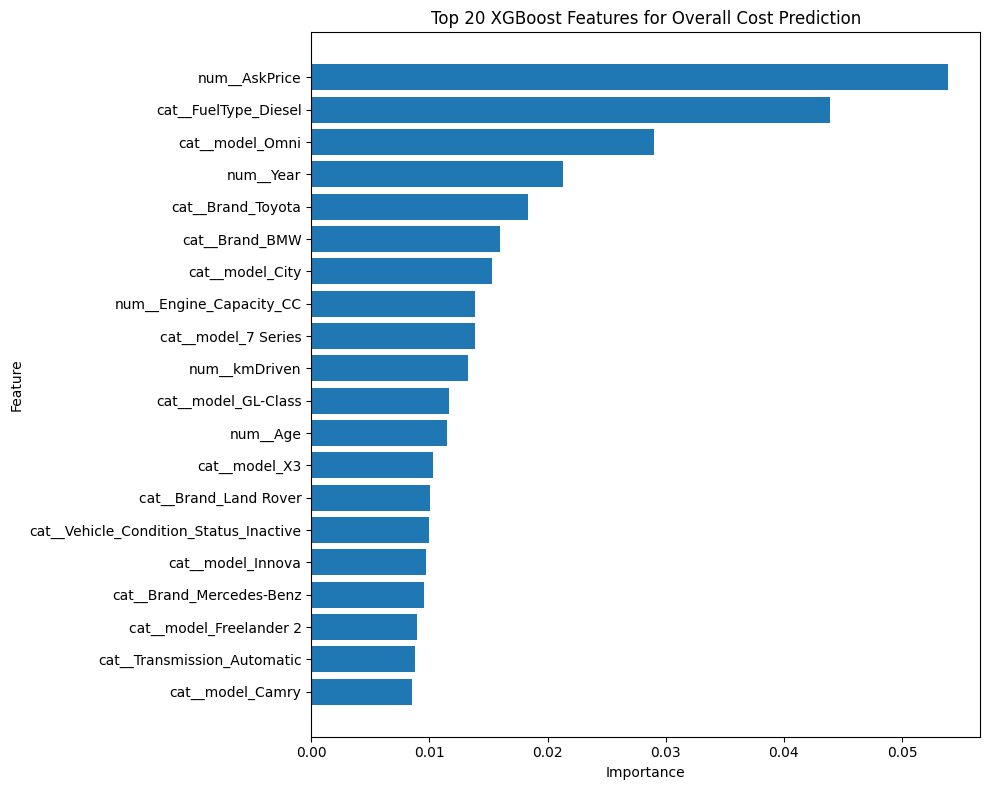

In [59]:
import matplotlib.pyplot as plt

print("========== TOP 20 FEATURE IMPORTANCE ==========")

top_features_used = feature_importance_used.head(20).sort_values(
    "Importance"
)

plt.figure(figsize=(10, 8))

plt.barh(
    top_features_used["Feature"],
    top_features_used["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 20 XGBoost Features for Overall Cost Prediction")

plt.tight_layout()
plt.show()

In [60]:
print("========== COST RANGE MODEL VALIDATION ==========")

validation_results_used = pd.DataFrame({
    "Actual_Cost": y_test_used.values,
    "Predicted_Cost": y_pred_xgb_tuned_used
})

validation_results_used["Absolute_Error"] = (
    validation_results_used["Actual_Cost"]
    - validation_results_used["Predicted_Cost"]
).abs()

validation_results_used["Cost_Group"] = pd.cut(
    validation_results_used["Actual_Cost"],
    bins=[-float("inf"), 5000, 10000, 15000, 20000, 30000, float("inf")],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

cost_range_validation_used = (
    validation_results_used
    .groupby("Cost_Group", observed=False)
    .agg(
        Count=("Actual_Cost", "count"),
        MAE=("Absolute_Error", "mean"),
        Actual_Mean=("Actual_Cost", "mean"),
        Predicted_Mean=("Predicted_Cost", "mean")
    )
)

display(cost_range_validation_used)

========== COST RANGE MODEL VALIDATION ==========


,Count,MAE,Actual_Mean,Predicted_Mean
Cost_Group,,,,
<=5K,194,7928.336660,3863.917526,11790.043945
5K-10K,769,5427.571457,7661.378414,12992.381836
10K-15K,774,2954.608243,12631.653747,14664.404297
15K-20K,573,2406.370598,17374.869110,15680.380859
20K-30K,558,7208.590652,23912.007168,16714.414062
>30K,129,16001.767109,34046.511628,18044.744141


In [61]:
print("========== TUNED XGBOOST ACTUAL VS PREDICTED ==========")

tuned_results_used = pd.DataFrame({
    "Actual Cost": y_test_used.values,
    "Predicted Cost": y_pred_xgb_tuned_used
})

tuned_results_used["Error"] = (
    tuned_results_used["Actual Cost"]
    - tuned_results_used["Predicted Cost"]
)

tuned_results_used["Absolute Error"] = (
    tuned_results_used["Error"].abs()
)

display(
    tuned_results_used.head(20)
)

========== TUNED XGBOOST ACTUAL VS PREDICTED ==========


,Actual Cost,Predicted Cost,Error,Absolute Error
0,20300.0,15953.657227,4346.342773,4346.342773
1,14000.0,12135.013672,1864.986328,1864.986328
2,18600.0,16366.752930,2233.247070,2233.247070
3,7500.0,7846.464355,-346.464355,346.464355
4,21600.0,19467.615234,2132.384766,2132.384766
5,5200.0,13897.313477,-8697.313477,8697.313477
6,14000.0,12017.184570,1982.815430,1982.815430
7,5700.0,14371.592773,-8671.592773,8671.592773
8,15100.0,16525.343750,-1425.343750,1425.343750
9,21500.0,16976.427734,4523.572266,4523.572266


In [62]:
print("========== XGBOOST WITH LOG TARGET ==========")

import numpy as np
import time

# Log transform target
y_train_log_used = np.log1p(y_train_used)

print("Original target mean:", round(y_train_used.mean(), 2))
print("Log target mean:", round(y_train_log_used.mean(), 4))

# Create model using the best parameters found earlier
xgb_log_used = XGBRegressor(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.03,
    subsample=0.9,
    colsample_bytree=0.7,
    min_child_weight=3,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Train
start_time = time.time()

xgb_log_used.fit(
    X_train_used_processed,
    y_train_log_used
)

training_time_log_used = time.time() - start_time

print("Training completed successfully!")
print("Training time:", round(training_time_log_used, 2), "seconds")

========== XGBOOST WITH LOG TARGET ==========
Original target mean: 14730.37
Log target mean: 9.4491
Training completed successfully!
Training time: 0.19 seconds


In [63]:
print("========== LOG XGBOOST PREDICTIONS ==========")

# Predict log cost
y_pred_log_used = xgb_log_used.predict(
    X_test_used_processed
)

# Convert back to original cost
y_pred_xgb_log_used = np.expm1(
    y_pred_log_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_log_used[:10])

========== LOG XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[14013.874  11847.553  14490.1875  7526.6357 16467.357  11902.358
 11643.94   12450.625  14474.303  14718.601 ]


In [64]:
print("========== LOG XGBOOST EVALUATION ==========")

mae_xgb_log_used = mean_absolute_error(
    y_test_used,
    y_pred_xgb_log_used
)

rmse_xgb_log_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_xgb_log_used
    )
)

r2_xgb_log_used = r2_score(
    y_test_used,
    y_pred_xgb_log_used
)

print("MAE :", round(mae_xgb_log_used, 4))
print("RMSE:", round(rmse_xgb_log_used, 4))
print("R²  :", round(r2_xgb_log_used, 4))

========== LOG XGBOOST EVALUATION ==========
MAE : 5247.0753
RMSE: 7001.8523
R²  : 0.1562


In [65]:
print("========== TUNED VS LOG XGBOOST ==========")

xgb_log_comparison_used = pd.DataFrame({
    "Model": [
        "Tuned XGBoost",
        "Log Target XGBoost"
    ],
    
    "MAE": [
        mae_xgb_tuned_used,
        mae_xgb_log_used
    ],
    
    "RMSE": [
        rmse_xgb_tuned_used,
        rmse_xgb_log_used
    ],
    
    "R2": [
        r2_xgb_tuned_used,
        r2_xgb_log_used
    ]
})

display(
    xgb_log_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== TUNED VS LOG XGBOOST ==========


,Model,MAE,RMSE,R2
0,Tuned XGBoost,5159.906052,6768.189686,0.211583
1,Log Target XGBoost,5247.075291,7001.852294,0.156205


In [66]:
print("========== SECOND XGBOOST HYPERPARAMETER TUNING ==========")

from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
import time

xgb_tuning_model_used = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

param_dist_xgb_2_used = {
    "n_estimators": [200, 300, 400, 500],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.02, 0.03, 0.05, 0.07],
    "min_child_weight": [1, 3, 5, 7],
    "subsample": [0.8, 0.9, 1.0],
    "colsample_bytree": [0.6, 0.7, 0.8, 0.9],
    "gamma": [0, 0.1, 0.2, 0.5]
}

random_search_xgb_2_used = RandomizedSearchCV(
    estimator=xgb_tuning_model_used,
    param_distributions=param_dist_xgb_2_used,
    n_iter=30,
    scoring="neg_root_mean_squared_error",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

print("Second tuning configuration created successfully!")

========== SECOND XGBOOST HYPERPARAMETER TUNING ==========
Second tuning configuration created successfully!


In [67]:
print("========== STARTING SECOND XGBOOST TUNING ==========")

start_time = time.time()

random_search_xgb_2_used.fit(
    X_train_used_processed,
    y_train_used
)

tuning_time_xgb_2_used = time.time() - start_time

print("Tuning completed successfully!")
print(
    "Tuning time:",
    round(tuning_time_xgb_2_used, 2),
    "seconds"
)

========== STARTING SECOND XGBOOST TUNING ==========
Fitting 3 folds for each of 30 candidates, totalling 90 fits
Tuning completed successfully!
Tuning time: 11.79 seconds


In [68]:
print("========== SECOND TUNING BEST PARAMETERS ==========")

print("Best parameters:")
print(random_search_xgb_2_used.best_params_)

print("\nBest CV RMSE:")
print(
    round(
        -random_search_xgb_2_used.best_score_,
        4
    )
)

========== SECOND TUNING BEST PARAMETERS ==========
Best parameters:
{'subsample': 0.9, 'n_estimators': 200, 'min_child_weight': 7, 'max_depth': 3, 'learning_rate': 0.02, 'gamma': 0.1, 'colsample_bytree': 0.8}

Best CV RMSE:
6814.6382


In [69]:
print("========== SECOND TUNED XGBOOST EVALUATION ==========")

best_xgb_2_used = random_search_xgb_2_used.best_estimator_

y_pred_xgb_2_used = best_xgb_2_used.predict(
    X_test_used_processed
)

mae_xgb_2_used = mean_absolute_error(
    y_test_used,
    y_pred_xgb_2_used
)

rmse_xgb_2_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_xgb_2_used
    )
)

r2_xgb_2_used = r2_score(
    y_test_used,
    y_pred_xgb_2_used
)

print("MAE :", round(mae_xgb_2_used, 4))
print("RMSE:", round(rmse_xgb_2_used, 4))
print("R²  :", round(r2_xgb_2_used, 4))

========== SECOND TUNED XGBOOST EVALUATION ==========
MAE : 5157.5933
RMSE: 6768.0368
R²  : 0.2116


In [70]:
print("========== FINAL XGBOOST COMPARISON ==========")

final_xgb_comparison_used = pd.DataFrame({
    "Model": [
        "Baseline XGBoost",
        "Tuned XGBoost",
        "Second Tuned XGBoost"
    ],

    "MAE": [
        mae_xgb_used,
        mae_xgb_tuned_used,
        mae_xgb_2_used
    ],

    "RMSE": [
        rmse_xgb_used,
        rmse_xgb_tuned_used,
        rmse_xgb_2_used
    ],

    "R2": [
        r2_xgb_used,
        r2_xgb_tuned_used,
        r2_xgb_2_used
    ]
})

display(
    final_xgb_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)


========== FINAL XGBOOST COMPARISON ==========


,Model,MAE,RMSE,R2
0,Second Tuned XGBoost,5157.593270,6768.036805,0.211618
1,Tuned XGBoost,5159.906052,6768.189686,0.211583
2,Baseline XGBoost,5170.078528,6823.805493,0.198572


In [72]:
print("========== SECOND TUNED XGBOOST COST RANGE VALIDATION ==========")

# Create validation dataframe
cost_range_results_2_used = pd.DataFrame({
    "Actual_Cost": y_test_used.values,
    "Predicted_Cost": y_pred_xgb_2_used
})

# Create the same cost groups
cost_range_results_2_used["Cost_Group"] = pd.cut(
    cost_range_results_2_used["Actual_Cost"],
    bins=[-np.inf, 5000, 10000, 15000, 20000, 30000, np.inf],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

# Calculate MAE and means
cost_range_validation_2_used = (
    cost_range_results_2_used
    .groupby("Cost_Group", observed=False)
    .apply(
        lambda group: pd.Series({
            "Count": len(group),
            "MAE": mean_absolute_error(
                group["Actual_Cost"],
                group["Predicted_Cost"]
            ),
            "Actual_Mean": group["Actual_Cost"].mean(),
            "Predicted_Mean": group["Predicted_Cost"].mean()
        })
    )
)

display(
    cost_range_validation_2_used
)

========== SECOND TUNED XGBOOST COST RANGE VALIDATION ==========


C:\Users\yaswa\AppData\Local\Temp\ipykernel_31704\3672073800.py:27: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Count,MAE,Actual_Mean,Predicted_Mean
Cost_Group,,,,
<=5K,194.0,7963.626119,3863.917526,11827.543945
5K-10K,769.0,5437.913971,7661.378414,13026.473633
10K-15K,774.0,2893.105430,12631.653747,14676.892578
15K-20K,573.0,2366.420022,17374.869110,15674.066406
20K-30K,558.0,7246.155363,23912.007168,16670.613281
>30K,129.0,16217.292643,34046.511628,17829.220703


In [73]:
print("========== COST RANGE ERROR ANALYSIS ==========")

cost_range_validation_2_used["Mean_Error"] = (
    cost_range_validation_2_used["Predicted_Mean"]
    - cost_range_validation_2_used["Actual_Mean"]
)

display(
    cost_range_validation_2_used
)

========== COST RANGE ERROR ANALYSIS ==========


,Count,MAE,Actual_Mean,Predicted_Mean,Mean_Error
Cost_Group,,,,,
<=5K,194.0,7963.626119,3863.917526,11827.543945,7963.626420
5K-10K,769.0,5437.913971,7661.378414,13026.473633,5365.095219
10K-15K,774.0,2893.105430,12631.653747,14676.892578,2045.238831
15K-20K,573.0,2366.420022,17374.869110,15674.066406,-1700.802704
20K-30K,558.0,7246.155363,23912.007168,16670.613281,-7241.393887
>30K,129.0,16217.292643,34046.511628,17829.220703,-16217.290925


In [74]:
print("========== CREATING SAMPLE WEIGHTS ==========")

# Create cost groups for training data
train_cost_groups_used = pd.cut(
    y_train_used,
    bins=[-np.inf, 5000, 10000, 15000, 20000, 30000, np.inf],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

# Assign weights
weight_mapping_used = {
    "<=5K": 2.0,
    "5K-10K": 1.2,
    "10K-15K": 1.0,
    "15K-20K": 1.0,
    "20K-30K": 1.2,
    ">30K": 2.0
}

sample_weights_used = (
    train_cost_groups_used
    .map(weight_mapping_used)
    .astype(float)
    .values
)

print("Sample weights created successfully!")

print("\nWeight distribution:")
print(
    pd.Series(sample_weights_used)
    .value_counts()
    .sort_index()
)

========== CREATING SAMPLE WEIGHTS ==========
Sample weights created successfully!

Weight distribution:
1.0    5372
1.2    5309
2.0    1306
Name: count, dtype: int64


In [75]:
print("========== CREATING WEIGHTED XGBOOST ==========")

weighted_xgb_used = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.02,
    min_child_weight=7,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Weighted XGBoost created successfully!")

========== CREATING WEIGHTED XGBOOST ==========
Weighted XGBoost created successfully!


In [76]:
print("========== TRAINING WEIGHTED XGBOOST ==========")

start_time = time.time()

weighted_xgb_used.fit(
    X_train_used_processed,
    y_train_used,
    sample_weight=sample_weights_used
)

weighted_training_time_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(weighted_training_time_used, 2),
    "seconds"
)

========== TRAINING WEIGHTED XGBOOST ==========
Training completed successfully!
Training time: 0.16 seconds


In [77]:
print("========== WEIGHTED XGBOOST PREDICTIONS ==========")

y_pred_weighted_xgb_used = weighted_xgb_used.predict(
    X_test_used_processed
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_weighted_xgb_used[:10])

========== WEIGHTED XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[15972.716  11760.332  16535.555   7691.2275 19838.121  13363.037
 11858.887  14049.365  17008.098  17464.857 ]


In [78]:
print("========== WEIGHTED XGBOOST EVALUATION ==========")

mae_weighted_xgb_used = mean_absolute_error(
    y_test_used,
    y_pred_weighted_xgb_used
)

rmse_weighted_xgb_used = np.sqrt(
    mean_squared_error(
        y_test_used,
        y_pred_weighted_xgb_used
    )
)

r2_weighted_xgb_used = r2_score(
    y_test_used,
    y_pred_weighted_xgb_used
)

print("MAE :", round(mae_weighted_xgb_used, 4))
print("RMSE:", round(rmse_weighted_xgb_used, 4))
print("R²  :", round(r2_weighted_xgb_used, 4))

========== WEIGHTED XGBOOST EVALUATION ==========
MAE : 5235.0105
RMSE: 6796.8252
R²  : 0.2049


In [79]:
print("========== WEIGHTED VS NORMAL XGBOOST ==========")

weighted_comparison_used = pd.DataFrame({
    "Model": [
        "Second Tuned XGBoost",
        "Weighted XGBoost"
    ],

    "MAE": [
        mae_xgb_2_used,
        mae_weighted_xgb_used
    ],

    "RMSE": [
        rmse_xgb_2_used,
        rmse_weighted_xgb_used
    ],

    "R2": [
        r2_xgb_2_used,
        r2_weighted_xgb_used
    ]
})

display(
    weighted_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== WEIGHTED VS NORMAL XGBOOST ==========


,Model,MAE,RMSE,R2
0,Second Tuned XGBoost,5157.593270,6768.036805,0.211618
1,Weighted XGBoost,5235.010481,6796.825246,0.204897


In [80]:
print("========== WEIGHTED XGBOOST COST RANGE VALIDATION ==========")

weighted_range_results_used = pd.DataFrame({
    "Actual_Cost": y_test_used.values,
    "Predicted_Cost": y_pred_weighted_xgb_used
})

weighted_range_results_used["Cost_Group"] = pd.cut(
    weighted_range_results_used["Actual_Cost"],
    bins=[
        -np.inf,
        5000,
        10000,
        15000,
        20000,
        30000,
        np.inf
    ],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

weighted_range_validation_used = (
    weighted_range_results_used
    .groupby("Cost_Group", observed=False)
    .apply(
        lambda group: pd.Series({
            "Count": len(group),
            "MAE": mean_absolute_error(
                group["Actual_Cost"],
                group["Predicted_Cost"]
            ),
            "Actual_Mean": group["Actual_Cost"].mean(),
            "Predicted_Mean": group["Predicted_Cost"].mean()
        })
    )
)

weighted_range_validation_used["Mean_Error"] = (
    weighted_range_validation_used["Predicted_Mean"]
    - weighted_range_validation_used["Actual_Mean"]
)

display(weighted_range_validation_used)

========== WEIGHTED XGBOOST COST RANGE VALIDATION ==========


C:\Users\yaswa\AppData\Local\Temp\ipykernel_31704\1987492868.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Count,MAE,Actual_Mean,Predicted_Mean,Mean_Error
Cost_Group,,,,,
<=5K,194.0,7946.687442,3863.917526,11810.605469,7946.687943
5K-10K,769.0,5458.028657,7661.378414,13027.664062,5366.285649
10K-15K,774.0,3219.006489,12631.653747,14716.880859,2085.227113
15K-20K,573.0,2793.634916,17374.869110,15646.924805,-1727.944305
20K-30K,558.0,6983.685535,23912.007168,16981.480469,-6930.526700
>30K,129.0,15203.757002,34046.511628,18842.755859,-15203.755769


In [81]:
print("========== CREATING ENGINEERED FEATURES ==========")

used_car_fe = used_car_df.copy()

# 1. Vehicle age based on manufacturing year
used_car_fe["Vehicle_Age"] = 2024 - used_car_fe["Year"]

# 2. Kilometers driven per year
used_car_fe["KM_Per_Year"] = (
    used_car_fe["kmDriven"] /
    used_car_fe["Vehicle_Age"].replace(0, 1)
)

# 3. Log transformation of highly skewed numerical features
used_car_fe["Log_kmDriven"] = np.log1p(
    used_car_fe["kmDriven"]
)

used_car_fe["Log_AskPrice"] = np.log1p(
    used_car_fe["AskPrice"]
)

# 4. Engine capacity per seat
used_car_fe["Engine_Per_Seat"] = (
    used_car_fe["Engine_Capacity_CC"] /
    used_car_fe["Seating_Capacity"]
)

# 5. Age × mileage interaction
used_car_fe["Age_KM_Interaction"] = (
    used_car_fe["Vehicle_Age"] *
    used_car_fe["kmDriven"]
)

# 6. Engine × age interaction
used_car_fe["Engine_Age_Interaction"] = (
    used_car_fe["Engine_Capacity_CC"] *
    used_car_fe["Vehicle_Age"]
)

print("Engineered features created successfully!")

new_features_used = [
    "Vehicle_Age",
    "KM_Per_Year",
    "Log_kmDriven",
    "Log_AskPrice",
    "Engine_Per_Seat",
    "Age_KM_Interaction",
    "Engine_Age_Interaction"
]

display(
    used_car_fe[
        new_features_used
    ].head(10)
)

========== CREATING ENGINEERED FEATURES ==========
Engineered features created successfully!


,Vehicle_Age,KM_Per_Year,Log_kmDriven,Log_AskPrice,Engine_Per_Seat,Age_KM_Interaction,Engine_Age_Interaction
0,23,4260.869565,11.492733,12.180760,299.400000,2254000.0,34431
1,15,12666.666667,12.154785,12.834684,356.285714,2850000.0,37410
2,14,5517.571429,11.254763,12.128111,239.600000,1081444.0,16772
3,7,11928.571429,11.332614,13.244583,239.400000,584500.0,8379
4,5,9000.000000,10.714440,13.437176,239.400000,225000.0,5985
5,10,8300.000000,11.326608,14.115616,399.600000,830000.0,19980
6,10,16800.000000,12.031725,13.840204,315.375000,1680000.0,25230
7,5,5000.000000,10.126671,15.598902,595.800000,125000.0,14895
8,4,8439.750000,10.427032,13.340697,239.600000,135036.0,4792
9,7,9959.000000,11.152156,13.383190,299.400000,487991.0,10479


In [82]:
print("========== ENGINEERED FEATURE VALIDATION ==========")

display(
    used_car_fe[new_features_used].describe()
)

print("\nMissing values:")

display(
    used_car_fe[new_features_used].isnull().sum()
)

print("\nInfinite values:")

print(
    np.isinf(
        used_car_fe[new_features_used]
        .select_dtypes(include=np.number)
    ).sum().sum()
)

========== ENGINEERED FEATURE VALIDATION ==========


,Vehicle_Age,KM_Per_Year,Log_kmDriven,Log_AskPrice,Engine_Per_Seat,Age_KM_Interaction,Engine_Age_Interaction
count,14984.000000,14984.000000,14984.000000,14984.000000,14984.000000,1.498400e+04,14984.000000
mean,7.657435,11283.337096,10.866891,13.321294,280.194938,6.075803e+05,11368.371997
std,4.106331,12304.603966,1.193953,0.919992,105.806013,6.245554e+05,7510.248975
min,0.000000,0.000000,0.000000,9.615872,99.666667,0.000000e+00,0.000000
25%,5.000000,6240.225000,10.714440,12.762830,213.857143,2.200000e+05,5994.000000
50%,7.000000,8900.000000,11.089821,13.253393,239.800000,4.830000e+05,9975.000000
75%,10.000000,12875.000000,11.360412,13.840204,311.750000,8.250000e+05,14976.000000
max,46.000000,450750.000000,13.795311,17.565015,1687.250000,1.280000e+07,91586.000000



Missing values:


Vehicle_Age               0
KM_Per_Year               0
Log_kmDriven              0
Log_AskPrice              0
Engine_Per_Seat           0
Age_KM_Interaction        0
Engine_Age_Interaction    0
dtype: int64


Infinite values:
0


In [83]:
print("========== CREATING FEATURE-ENGINEERED ML DATASET ==========")

# Original 20 features
base_features_used = selected_features.copy()

# Add engineered features
engineered_features_used = (
    base_features_used +
    new_features_used
)

# Remove duplicates if any
engineered_features_used = list(
    dict.fromkeys(engineered_features_used)
)

X_fe_used = used_car_fe[
    engineered_features_used
].copy()

y_fe_used = used_car_fe[
    target
].copy()

print("Original features:", len(base_features_used))
print("Engineered features:", len(new_features_used))
print("Total features:", len(engineered_features_used))

print("\nX shape:", X_fe_used.shape)
print("y shape:", y_fe_used.shape)

print("\nNew features:")
for i, feature in enumerate(
    new_features_used, 1
):
    print(i, ".", feature)

========== CREATING FEATURE-ENGINEERED ML DATASET ==========
Original features: 20
Engineered features: 7
Total features: 27

X shape: (14984, 27)
y shape: (14984,)

New features:
1 . Vehicle_Age
2 . KM_Per_Year
3 . Log_kmDriven
4 . Log_AskPrice
5 . Engine_Per_Seat
6 . Age_KM_Interaction
7 . Engine_Age_Interaction


In [84]:
print("========== COMPLETE FEATURE VALIDATION ==========")

print("Missing values in X:")

print(
    X_fe_used.isnull().sum().sum()
)

print("\nMissing values in y:")

print(
    y_fe_used.isnull().sum()
)

print("\nDuplicate rows:")

print(
    X_fe_used.duplicated().sum()
)

print("\nFeature data types:")

display(
    X_fe_used.dtypes
)

========== COMPLETE FEATURE VALIDATION ==========
Missing values in X:
0

Missing values in y:
0

Duplicate rows:
80

Feature data types:


Brand                        object
model                        object
Year                          int64
Age                           int64
Engine_Capacity_CC            int64
Seating_Capacity              int64
Transmission                 object
FuelType                     object
Owner                        object
kmDriven                    float64
Exterior_Body_Color          object
Interior_Body_Color          object
Has_Insurance                object
Vehicle_Condition_Status     object
AskPrice                    float64
Posted_Year                   int32
Posted_Month                  int32
Posted_Quarter                int32
Posted_Weekday                int32
Posted_Is_Weekend             int64
Vehicle_Age                   int64
KM_Per_Year                 float64
Log_kmDriven                float64
Log_AskPrice                float64
Engine_Per_Seat             float64
Age_KM_Interaction          float64
Engine_Age_Interaction        int64
dtype: object

In [85]:
print("========== FEATURE-ENGINEERED TRAIN TEST SPLIT ==========")

from sklearn.model_selection import train_test_split

X_train_fe_used, X_test_fe_used, \
y_train_fe_used, y_test_fe_used = train_test_split(
    X_fe_used,
    y_fe_used,
    test_size=0.20,
    random_state=42
)

print("Training data:")
print("X_train:", X_train_fe_used.shape)
print("y_train:", y_train_fe_used.shape)

print("\nTesting data:")
print("X_test :", X_test_fe_used.shape)
print("y_test :", y_test_fe_used.shape)

print("\nTraining target mean:",
      round(y_train_fe_used.mean(), 2))

print("Testing target mean :",
      round(y_test_fe_used.mean(), 2))

========== FEATURE-ENGINEERED TRAIN TEST SPLIT ==========
Training data:
X_train: (11987, 27)
y_train: (11987,)

Testing data:
X_test : (2997, 27)
y_test : (2997,)

Training target mean: 14730.37
Testing target mean : 14717.65


In [86]:
print("========== DEFINING FEATURE-ENGINEERED PREPROCESSING ==========")

numerical_features_fe_used = [
    "Year",
    "Age",
    "Engine_Capacity_CC",
    "Seating_Capacity",
    "kmDriven",
    "AskPrice",
    "Posted_Year",
    "Posted_Month",
    "Posted_Quarter",
    "Posted_Weekday",
    "Posted_Is_Weekend",
    "Vehicle_Age",
    "KM_Per_Year",
    "Log_kmDriven",
    "Log_AskPrice",
    "Engine_Per_Seat",
    "Age_KM_Interaction",
    "Engine_Age_Interaction"
]

categorical_features_fe_used = [
    "Brand",
    "model",
    "Transmission",
    "FuelType",
    "Owner",
    "Exterior_Body_Color",
    "Interior_Body_Color",
    "Has_Insurance",
    "Vehicle_Condition_Status"
]

print("Numerical features:",
      len(numerical_features_fe_used))

print("Categorical features:",
      len(categorical_features_fe_used))

print("\nNumerical features:")
print(numerical_features_fe_used)

print("\nCategorical features:")
print(categorical_features_fe_used)

========== DEFINING FEATURE-ENGINEERED PREPROCESSING ==========
Numerical features: 18
Categorical features: 9

Numerical features:
['Year', 'Age', 'Engine_Capacity_CC', 'Seating_Capacity', 'kmDriven', 'AskPrice', 'Posted_Year', 'Posted_Month', 'Posted_Quarter', 'Posted_Weekday', 'Posted_Is_Weekend', 'Vehicle_Age', 'KM_Per_Year', 'Log_kmDriven', 'Log_AskPrice', 'Engine_Per_Seat', 'Age_KM_Interaction', 'Engine_Age_Interaction']

Categorical features:
['Brand', 'model', 'Transmission', 'FuelType', 'Owner', 'Exterior_Body_Color', 'Interior_Body_Color', 'Has_Insurance', 'Vehicle_Condition_Status']


In [87]:
print("========== CREATING FEATURE-ENGINEERED PREPROCESSING PIPELINE ==========")

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical pipeline
numeric_pipeline_fe_used = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median")
    )
])

# Categorical pipeline
categorical_pipeline_fe_used = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="most_frequent")
    ),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore"
        )
    )
])

# Combined preprocessor
preprocessor_fe_used = ColumnTransformer([
    (
        "num",
        numeric_pipeline_fe_used,
        numerical_features_fe_used
    ),
    (
        "cat",
        categorical_pipeline_fe_used,
        categorical_features_fe_used
    )
])

print("Feature-engineered preprocessing pipeline created successfully!")

========== CREATING FEATURE-ENGINEERED PREPROCESSING PIPELINE ==========
Feature-engineered preprocessing pipeline created successfully!


In [88]:
print("========== FITTING FEATURE-ENGINEERED PREPROCESSOR ==========")

X_train_fe_processed_used = (
    preprocessor_fe_used.fit_transform(
        X_train_fe_used
    )
)

print(
    "Processed training shape:",
    X_train_fe_processed_used.shape
)

========== FITTING FEATURE-ENGINEERED PREPROCESSOR ==========
Processed training shape: (11987, 503)


In [89]:
print("========== TRANSFORMING FEATURE-ENGINEERED TEST DATA ==========")

X_test_fe_processed_used = (
    preprocessor_fe_used.transform(
        X_test_fe_used
    )
)

print(
    "Processed testing shape:",
    X_test_fe_processed_used.shape
)

========== TRANSFORMING FEATURE-ENGINEERED TEST DATA ==========
Processed testing shape: (2997, 503)


In [90]:
print("========== FEATURE-ENGINEERED PREPROCESSING VALIDATION ==========")

print(
    "Original training features:",
    X_train_fe_used.shape[1]
)

print(
    "Processed training features:",
    X_train_fe_processed_used.shape[1]
)

print(
    "\nOriginal testing features:",
    X_test_fe_used.shape[1]
)

print(
    "Processed testing features:",
    X_test_fe_processed_used.shape[1]
)

print(
    "\nTraining samples:",
    X_train_fe_processed_used.shape[0]
)

print(
    "Testing samples:",
    X_test_fe_processed_used.shape[0]
)

========== FEATURE-ENGINEERED PREPROCESSING VALIDATION ==========
Original training features: 27
Processed training features: 503

Original testing features: 27
Processed testing features: 503

Training samples: 11987
Testing samples: 2997


In [91]:
print("========== TRAINING FEATURE-ENGINEERED XGBOOST ==========")

from xgboost import XGBRegressor
import time

xgb_fe_used = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.02,
    min_child_weight=7,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_fe_used.fit(
    X_train_fe_processed_used,
    y_train_fe_used
)

training_time_fe_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(training_time_fe_used, 2),
    "seconds"
)

========== TRAINING FEATURE-ENGINEERED XGBOOST ==========
Training completed successfully!
Training time: 0.43 seconds


In [92]:
print("========== FEATURE-ENGINEERED XGBOOST PREDICTIONS ==========")

y_pred_xgb_fe_used = xgb_fe_used.predict(
    X_test_fe_processed_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_fe_used[:10])

========== FEATURE-ENGINEERED XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[15576.301 12232.591 16681.39   7575.033 18889.73  13381.767 12087.222
 14650.411 16768.598 17090.174]


In [93]:
print("========== FEATURE-ENGINEERED XGBOOST EVALUATION ==========")

mae_xgb_fe_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_xgb_fe_used
)

rmse_xgb_fe_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_xgb_fe_used
    )
)

r2_xgb_fe_used = r2_score(
    y_test_fe_used,
    y_pred_xgb_fe_used
)

print("MAE :", round(mae_xgb_fe_used, 4))
print("RMSE:", round(rmse_xgb_fe_used, 4))
print("R²  :", round(r2_xgb_fe_used, 4))

========== FEATURE-ENGINEERED XGBOOST EVALUATION ==========
MAE : 5147.1581
RMSE: 6758.4888
R²  : 0.2138


In [94]:
print("========== FEATURE-ENGINEERED FEATURE IMPORTANCE ==========")

feature_names_fe_used = (
    preprocessor_fe_used
    .get_feature_names_out()
)

feature_importance_fe_used = pd.DataFrame({
    "Feature": feature_names_fe_used,
    "Importance": xgb_fe_used.feature_importances_
})

feature_importance_fe_used = (
    feature_importance_fe_used
    .sort_values(
        "Importance",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    feature_importance_fe_used.head(30)
)

========== FEATURE-ENGINEERED FEATURE IMPORTANCE ==========


,Feature,Importance
0,num__AskPrice,0.138781
1,num__Log_AskPrice,0.110781
2,num__Age_KM_Interaction,0.068956
3,num__Engine_Age_Interaction,0.058060
4,num__Vehicle_Age,0.055684
5,num__Engine_Capacity_CC,0.037576
6,num__Age,0.030779
7,num__Year,0.029909
8,cat__Brand_Mercedes-Benz,0.020297
9,num__kmDriven,0.019249


In [95]:
print("========== NEW ENGINEERED FEATURES IMPORTANCE ==========")

engineered_importance_used = (
    feature_importance_fe_used[
        feature_importance_fe_used["Feature"].str.contains(
            "Vehicle_Age|KM_Per_Year|Log_kmDriven|Log_AskPrice|Engine_Per_Seat|Age_KM_Interaction|Engine_Age_Interaction",
            regex=True
        )
    ]
)

display(engineered_importance_used)

========== NEW ENGINEERED FEATURES IMPORTANCE ==========


,Feature,Importance
1,num__Log_AskPrice,0.110781
2,num__Age_KM_Interaction,0.068956
3,num__Engine_Age_Interaction,0.058060
4,num__Vehicle_Age,0.055684
11,num__Log_kmDriven,0.017055
18,num__Engine_Per_Seat,0.014182
28,num__KM_Per_Year,0.010315


In [96]:
print("========== TRAINING MAE-OBJECTIVE XGBOOST ==========")

xgb_mae_fe_used = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.02,
    min_child_weight=7,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    objective="reg:absoluteerror",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_mae_fe_used.fit(
    X_train_fe_processed_used,
    y_train_fe_used
)

training_time_mae_fe_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(training_time_mae_fe_used, 2),
    "seconds"
)

========== TRAINING MAE-OBJECTIVE XGBOOST ==========
Training completed successfully!
Training time: 1.37 seconds


In [97]:
print("========== MAE-OBJECTIVE XGBOOST PREDICTIONS ==========")

y_pred_xgb_mae_fe_used = xgb_mae_fe_used.predict(
    X_test_fe_processed_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_mae_fe_used[:10])

========== MAE-OBJECTIVE XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[14501.379  13917.655  15589.849   7636.9595 17141.365  12876.988
 13701.567  13900.25   15571.012  15944.846 ]


In [98]:
print("========== MAE-OBJECTIVE XGBOOST EVALUATION ==========")

mae_xgb_mae_fe_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_xgb_mae_fe_used
)

rmse_xgb_mae_fe_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_xgb_mae_fe_used
    )
)

r2_xgb_mae_fe_used = r2_score(
    y_test_fe_used,
    y_pred_xgb_mae_fe_used
)

print("MAE :", round(mae_xgb_mae_fe_used, 4))
print("RMSE:", round(rmse_xgb_mae_fe_used, 4))
print("R²  :", round(r2_xgb_mae_fe_used, 4))

========== MAE-OBJECTIVE XGBOOST EVALUATION ==========
MAE : 5013.4709
RMSE: 6883.7454
R²  : 0.1844


In [99]:
print("========== FINAL MODEL COMPARISON ==========")

model_comparison_final_used = pd.DataFrame({
    "Model": [
        "Second Tuned XGBoost",
        "Feature-Engineered XGBoost",
        "MAE Objective Feature-Engineered XGBoost"
    ],

    "MAE": [
        mae_xgb_2_used,
        mae_xgb_fe_used,
        mae_xgb_mae_fe_used
    ],

    "RMSE": [
        rmse_xgb_2_used,
        rmse_xgb_fe_used,
        rmse_xgb_mae_fe_used
    ],

    "R2": [
        r2_xgb_2_used,
        r2_xgb_fe_used,
        r2_xgb_mae_fe_used
    ]
})

display(
    model_comparison_final_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== FINAL MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Feature-Engineered XGBoost,5147.158137,6758.488759,0.213841
1,Second Tuned XGBoost,5157.593270,6768.036805,0.211618
2,MAE Objective Feature-Engineered XGBoost,5013.470909,6883.745385,0.184431


In [100]:
final_model_used = xgb_fe_used

In [101]:
X_test_fe_processed_used

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 77894 stored elements and shape (2997, 503)>

In [102]:
final_model_used.predict(X_test_fe_processed_used)

array([15576.301, 12232.591, 16681.39 , ..., 12765.869, 15598.732,
       24936.121], shape=(2997,), dtype=float32)

In [103]:
print("========== FINAL MODEL ACTUAL VS PREDICTED ==========")

final_results_used = pd.DataFrame({
    "Actual_Cost": y_test_fe_used.values,
    "Predicted_Cost": y_pred_xgb_fe_used
})

final_results_used["Error"] = (
    final_results_used["Actual_Cost"]
    - final_results_used["Predicted_Cost"]
)

final_results_used["Absolute_Error"] = (
    final_results_used["Error"].abs()
)

final_results_used["Percentage_Error"] = (
    final_results_used["Absolute_Error"]
    / final_results_used["Actual_Cost"]
) * 100

display(final_results_used.head(20))

========== FINAL MODEL ACTUAL VS PREDICTED ==========


,Actual_Cost,Predicted_Cost,Error,Absolute_Error,Percentage_Error
0,20300.0,15576.300781,4723.699219,4723.699219,23.269454
1,14000.0,12232.590820,1767.409180,1767.409180,12.624351
2,18600.0,16681.390625,1918.609375,1918.609375,10.315104
3,7500.0,7575.033203,-75.033203,75.033203,1.000443
4,21600.0,18889.730469,2710.269531,2710.269531,12.547544
5,5200.0,13381.766602,-8181.766602,8181.766602,157.341665
6,14000.0,12087.221680,1912.778320,1912.778320,13.662702
7,5700.0,14650.411133,-8950.411133,8950.411133,157.024757
8,15100.0,16768.597656,-1668.597656,1668.597656,11.050316
9,21500.0,17090.173828,4409.826172,4409.826172,20.510819


In [104]:
print("========== FINAL MODEL RESIDUAL ANALYSIS ==========")

print("Mean Error:",
      round(final_results_used["Error"].mean(), 4))

print("Mean Absolute Error:",
      round(final_results_used["Absolute_Error"].mean(), 4))

print("Minimum Error:",
      round(final_results_used["Error"].min(), 4))

print("Maximum Error:",
      round(final_results_used["Error"].max(), 4))

print("\nResidual statistics:")

display(
    final_results_used["Error"].describe()
)

========== FINAL MODEL RESIDUAL ANALYSIS ==========
Mean Error: -49.7724
Mean Absolute Error: 5147.1581
Minimum Error: -22096.8398
Maximum Error: 26766.2344

Residual statistics:


count     2997.000000
mean       -49.772358
std       6759.433278
min     -22096.839844
25%      -4746.591797
50%          7.623047
75%       3672.829102
max      26766.234375
Name: Error, dtype: float64

========== ACTUAL VS PREDICTED PLOT ==========


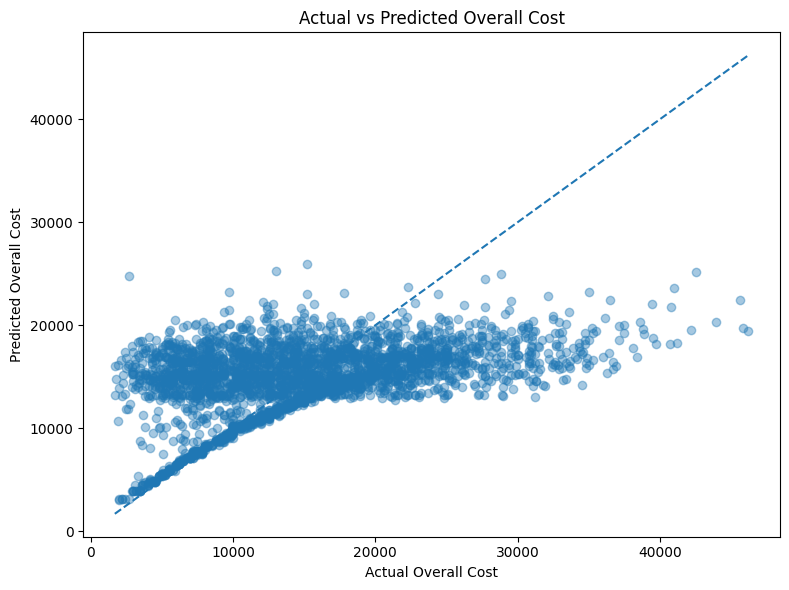

In [105]:
import matplotlib.pyplot as plt

print("========== ACTUAL VS PREDICTED PLOT ==========")

plt.figure(figsize=(8, 6))

plt.scatter(
    final_results_used["Actual_Cost"],
    final_results_used["Predicted_Cost"],
    alpha=0.4
)

plt.xlabel("Actual Overall Cost")
plt.ylabel("Predicted Overall Cost")
plt.title("Actual vs Predicted Overall Cost")

min_value = min(
    final_results_used["Actual_Cost"].min(),
    final_results_used["Predicted_Cost"].min()
)

max_value = max(
    final_results_used["Actual_Cost"].max(),
    final_results_used["Predicted_Cost"].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.tight_layout()
plt.show()

========== RESIDUAL PLOT ==========


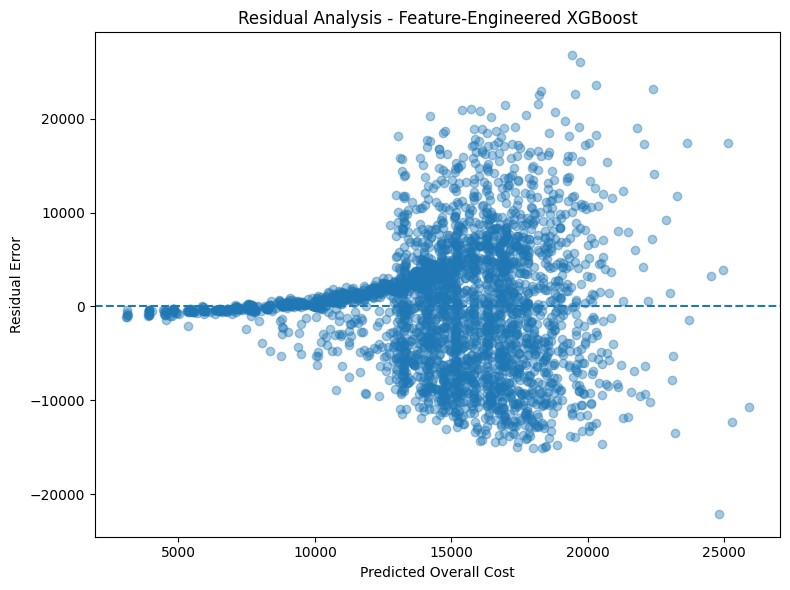

In [106]:
print("========== RESIDUAL PLOT ==========")

plt.figure(figsize=(8, 6))

plt.scatter(
    final_results_used["Predicted_Cost"],
    final_results_used["Error"],
    alpha=0.4
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Predicted Overall Cost")
plt.ylabel("Residual Error")
plt.title("Residual Analysis - Feature-Engineered XGBoost")

plt.tight_layout()
plt.show()

In [107]:
print("========== FINAL MODEL COST RANGE VALIDATION ==========")

final_range_results_used = pd.DataFrame({
    "Actual_Cost": y_test_fe_used.values,
    "Predicted_Cost": y_pred_xgb_fe_used
})

final_range_results_used["Cost_Group"] = pd.cut(
    final_range_results_used["Actual_Cost"],
    bins=[
        -np.inf,
        5000,
        10000,
        15000,
        20000,
        30000,
        np.inf
    ],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

final_range_validation_used = (
    final_range_results_used
    .groupby("Cost_Group", observed=False)
    .apply(
        lambda group: pd.Series({
            "Count": len(group),
            "MAE": mean_absolute_error(
                group["Actual_Cost"],
                group["Predicted_Cost"]
            ),
            "Actual_Mean": group["Actual_Cost"].mean(),
            "Predicted_Mean": group["Predicted_Cost"].mean()
        })
    )
)

final_range_validation_used["Mean_Error"] = (
    final_range_validation_used["Predicted_Mean"]
    - final_range_validation_used["Actual_Mean"]
)

display(final_range_validation_used)

========== FINAL MODEL COST RANGE VALIDATION ==========


C:\Users\yaswa\AppData\Local\Temp\ipykernel_31704\1775236574.py:32: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(


,Count,MAE,Actual_Mean,Predicted_Mean,Mean_Error
Cost_Group,,,,,
<=5K,194.0,7948.154813,3863.917526,11812.072266,7948.154740
5K-10K,769.0,5409.759136,7661.378414,13012.148438,5350.770024
10K-15K,774.0,2886.341181,12631.653747,14676.191406,2044.537659
15K-20K,573.0,2398.420895,17374.869110,15669.602539,-1705.266571
20K-30K,558.0,7229.199270,23912.007168,16687.810547,-7224.196622
>30K,129.0,16137.749523,34046.511628,17908.763672,-16137.747956


In [108]:
print("========== TARGET DISTRIBUTION ANALYSIS ==========")

print(y_fe_used.describe())

print("\nTarget skewness:")
print(round(y_fe_used.skew(), 4))

========== TARGET DISTRIBUTION ANALYSIS ==========
count    14984.000000
mean     14727.829685
std       7692.551011
min        800.000000
25%       8800.000000
50%      13500.000000
75%      19500.000000
max      47600.000000
Name: Overall_Cost, dtype: float64

Target skewness:
0.8048


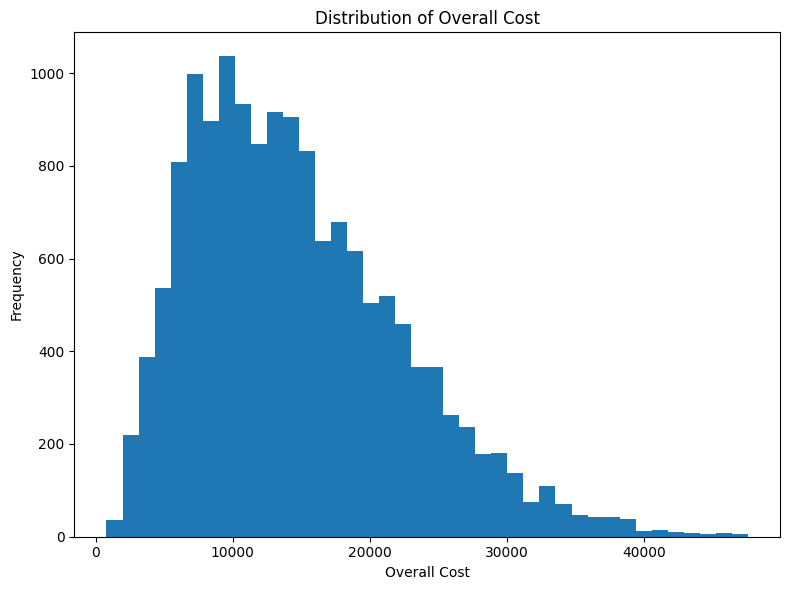

In [109]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.hist(y_fe_used, bins=40)

plt.xlabel("Overall Cost")
plt.ylabel("Frequency")
plt.title("Distribution of Overall Cost")

plt.tight_layout()
plt.show()

In [110]:
print("========== TRAINING TARGET COST DISTRIBUTION ==========")

train_cost_distribution_used = pd.cut(
    y_train_fe_used,
    bins=[
        -np.inf,
        5000,
        10000,
        15000,
        20000,
        30000,
        np.inf
    ],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

print(
    train_cost_distribution_used
    .value_counts()
    .sort_index()
)

========== TRAINING TARGET COST DISTRIBUTION ==========
Overall_Cost
<=5K        811
5K-10K     3082
10K-15K    3071
15K-20K    2301
20K-30K    2227
>30K        495
Name: count, dtype: int64


In [111]:
print("\n========== TRAINING TARGET PERCENTAGES ==========")

train_cost_distribution_used.value_counts(
    normalize=True
).sort_index().mul(100).round(2)


========== TRAINING TARGET PERCENTAGES ==========


Overall_Cost
<=5K        6.77
5K-10K     25.71
10K-15K    25.62
15K-20K    19.20
20K-30K    18.58
>30K        4.13
Name: proportion, dtype: float64

In [112]:
print("========== FEATURE-ENGINEERED LOG TARGET XGBOOST ==========")

from xgboost import XGBRegressor

xgb_log_fe_used = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.02,
    min_child_weight=7,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Log-target XGBoost created successfully!")

========== FEATURE-ENGINEERED LOG TARGET XGBOOST ==========
Log-target XGBoost created successfully!


In [113]:
print("========== TRAINING FEATURE-ENGINEERED LOG XGBOOST ==========")

start_time = time.time()

y_train_log_fe_used = np.log1p(
    y_train_fe_used
)

xgb_log_fe_used.fit(
    X_train_fe_processed_used,
    y_train_log_fe_used
)

training_time_log_fe_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(training_time_log_fe_used, 2),
    "seconds"
)

========== TRAINING FEATURE-ENGINEERED LOG XGBOOST ==========
Training completed successfully!
Training time: 0.68 seconds


In [114]:
print("========== FEATURE-ENGINEERED LOG XGBOOST PREDICTIONS ==========")

y_pred_xgb_log_fe_used = xgb_log_fe_used.predict(
    X_test_fe_processed_used
)

y_pred_xgb_log_fe_used = np.expm1(
    y_pred_xgb_log_fe_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_log_fe_used[:10])

========== FEATURE-ENGINEERED LOG XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[13400.326 11927.644 14633.513  7180.571 16063.439 11527.64  11690.086
 12708.023 14632.34  14681.378]


In [115]:
print("========== FEATURE-ENGINEERED LOG XGBOOST EVALUATION ==========")

mae_xgb_log_fe_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_xgb_log_fe_used
)

rmse_xgb_log_fe_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_xgb_log_fe_used
    )
)

r2_xgb_log_fe_used = r2_score(
    y_test_fe_used,
    y_pred_xgb_log_fe_used
)

print("MAE :", round(mae_xgb_log_fe_used, 4))
print("RMSE:", round(rmse_xgb_log_fe_used, 4))
print("R²  :", round(r2_xgb_log_fe_used, 4))

========== FEATURE-ENGINEERED LOG XGBOOST EVALUATION ==========
MAE : 5236.7158
RMSE: 7002.8811
R²  : 0.156


In [116]:
print("========== FEATURE-ENGINEERED MODEL COMPARISON ==========")

fe_model_comparison_used = pd.DataFrame({
    "Model": [
        "Feature-Engineered XGBoost",
        "Feature-Engineered Log XGBoost",
        "MAE Objective Feature-Engineered XGBoost"
    ],

    "MAE": [
        mae_xgb_fe_used,
        mae_xgb_log_fe_used,
        mae_xgb_mae_fe_used
    ],

    "RMSE": [
        rmse_xgb_fe_used,
        rmse_xgb_log_fe_used,
        rmse_xgb_mae_fe_used
    ],

    "R2": [
        r2_xgb_fe_used,
        r2_xgb_log_fe_used,
        r2_xgb_mae_fe_used
    ]
})

display(
    fe_model_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== FEATURE-ENGINEERED MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Feature-Engineered XGBoost,5147.158137,6758.488759,0.213841
1,MAE Objective Feature-Engineered XGBoost,5013.470909,6883.745385,0.184431
2,Feature-Engineered Log XGBoost,5236.715765,7002.881053,0.155957


In [117]:
print("========== FINAL MODEL COST RANGE ERROR PERCENTAGE ==========")

final_range_percentage_used = final_range_validation_used.copy()

final_range_percentage_used["Error_Percentage"] = (
    (
        final_range_percentage_used["Predicted_Mean"]
        - final_range_percentage_used["Actual_Mean"]
    )
    / final_range_percentage_used["Actual_Mean"]
) * 100

display(
    final_range_percentage_used[
        [
            "Count",
            "MAE",
            "Actual_Mean",
            "Predicted_Mean",
            "Mean_Error",
            "Error_Percentage"
        ]
    ]
)

========== FINAL MODEL COST RANGE ERROR PERCENTAGE ==========


,Count,MAE,Actual_Mean,Predicted_Mean,Mean_Error,Error_Percentage
Cost_Group,,,,,,
<=5K,194.0,7948.154813,3863.917526,11812.072266,7948.154740,205.701977
5K-10K,769.0,5409.759136,7661.378414,13012.148438,5350.770024,69.840827
10K-15K,774.0,2886.341181,12631.653747,14676.191406,2044.537659,16.185827
15K-20K,573.0,2398.420895,17374.869110,15669.602539,-1705.266571,-9.814558
20K-30K,558.0,7229.199270,23912.007168,16687.810547,-7224.196622,-30.211586
>30K,129.0,16137.749523,34046.511628,17908.763672,-16137.747956,-47.399123


In [118]:
print("========== PREDICTION RANGE ANALYSIS ==========")

print("Actual cost range:")
print(
    round(y_test_fe_used.min(), 2),
    "to",
    round(y_test_fe_used.max(), 2)
)

print("\nPredicted cost range:")
print(
    round(y_pred_xgb_fe_used.min(), 2),
    "to",
    round(y_pred_xgb_fe_used.max(), 2)
)

print("\nActual standard deviation:",
      round(y_test_fe_used.std(), 2))

print("Predicted standard deviation:",
      round(np.std(y_pred_xgb_fe_used), 2))

========== PREDICTION RANGE ANALYSIS ==========
Actual cost range:
1700.0 to 46200.0

Predicted cost range:
3074.96 to 25898.82

Actual standard deviation: 7623.72
Predicted standard deviation: 3442.07


In [119]:
print("========== ASK PRICE VS OVERALL COST ANALYSIS ==========")

askprice_analysis_used = pd.DataFrame({
    "AskPrice": X_test_fe_used["AskPrice"].values,
    "Actual_Cost": y_test_fe_used.values,
    "Predicted_Cost": y_pred_xgb_fe_used
})

print("AskPrice statistics:")
display(
    askprice_analysis_used["AskPrice"].describe()
)

print("\nCorrelation with Actual Cost:")
print(
    round(
        askprice_analysis_used[
            ["AskPrice", "Actual_Cost"]
        ].corr().loc["AskPrice", "Actual_Cost"],
        4
    )
)

========== ASK PRICE VS OVERALL COST ANALYSIS ==========
AskPrice statistics:


count    2.997000e+03
mean     9.706869e+05
std      1.339608e+06
min      4.000000e+04
25%      3.490000e+05
50%      5.750000e+05
75%      1.050000e+06
max      2.600000e+07
Name: AskPrice, dtype: float64


Correlation with Actual Cost:
0.1012


In [120]:
print("========== COST RANGE ASK PRICE ANALYSIS ==========")

askprice_analysis_used["Cost_Group"] = pd.cut(
    askprice_analysis_used["Actual_Cost"],
    bins=[
        -np.inf,
        5000,
        10000,
        15000,
        20000,
        30000,
        np.inf
    ],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

askprice_range_used = (
    askprice_analysis_used
    .groupby("Cost_Group", observed=False)
    .agg(
        Count=("AskPrice", "count"),
        AskPrice_Mean=("AskPrice", "mean"),
        Actual_Cost_Mean=("Actual_Cost", "mean"),
        Predicted_Cost_Mean=("Predicted_Cost", "mean")
    )
)

display(askprice_range_used)

========== COST RANGE ASK PRICE ANALYSIS ==========


,Count,AskPrice_Mean,Actual_Cost_Mean,Predicted_Cost_Mean
Cost_Group,,,,
<=5K,194,9.862067e+05,3863.917526,11812.072266
5K-10K,769,7.935969e+05,7661.378414,13012.148438
10K-15K,774,9.327827e+05,12631.653747,14676.192383
15K-20K,573,9.509925e+05,17374.869110,15669.603516
20K-30K,558,1.142884e+06,23912.007168,16687.810547
>30K,129,1.573077e+06,34046.511628,17908.761719


In [121]:
print("========== COST RANGE ASK PRICE ANALYSIS ==========")

askprice_analysis_used["Cost_Group"] = pd.cut(
    askprice_analysis_used["Actual_Cost"],
    bins=[
        -np.inf,
        5000,
        10000,
        15000,
        20000,
        30000,
        np.inf
    ],
    labels=[
        "<=5K",
        "5K-10K",
        "10K-15K",
        "15K-20K",
        "20K-30K",
        ">30K"
    ]
)

askprice_range_used = (
    askprice_analysis_used
    .groupby("Cost_Group", observed=False)
    .agg(
        Count=("AskPrice", "count"),
        AskPrice_Mean=("AskPrice", "mean"),
        Actual_Cost_Mean=("Actual_Cost", "mean"),
        Predicted_Cost_Mean=("Predicted_Cost", "mean")
    )
)

display(askprice_range_used)

========== COST RANGE ASK PRICE ANALYSIS ==========


,Count,AskPrice_Mean,Actual_Cost_Mean,Predicted_Cost_Mean
Cost_Group,,,,
<=5K,194,9.862067e+05,3863.917526,11812.072266
5K-10K,769,7.935969e+05,7661.378414,13012.148438
10K-15K,774,9.327827e+05,12631.653747,14676.192383
15K-20K,573,9.509925e+05,17374.869110,15669.603516
20K-30K,558,1.142884e+06,23912.007168,16687.810547
>30K,129,1.573077e+06,34046.511628,17908.761719


In [122]:
print("========== CREATING RESIDUAL DATASET ==========")

residual_analysis_used = X_test_fe_used.copy()

residual_analysis_used["Actual_Cost"] = y_test_fe_used.values

residual_analysis_used["Predicted_Cost"] = (
    y_pred_xgb_fe_used
)

residual_analysis_used["Residual"] = (
    residual_analysis_used["Actual_Cost"]
    - residual_analysis_used["Predicted_Cost"]
)

print("Residual dataset created successfully!")

display(
    residual_analysis_used[
        [
            "AskPrice",
            "Age",
            "kmDriven",
            "Engine_Capacity_CC",
            "Seating_Capacity",
            "Actual_Cost",
            "Predicted_Cost",
            "Residual"
        ]
    ].head(10)
)

========== CREATING RESIDUAL DATASET ==========
Residual dataset created successfully!


,AskPrice,Age,kmDriven,Engine_Capacity_CC,Seating_Capacity,Actual_Cost,Predicted_Cost,Residual
10005,1825000.0,7,35000.0,1798,5,20300.0,15576.300781,4723.699219
9470,280000.0,14,75000.0,796,5,14000.0,12232.590820,1767.409180
8600,525000.0,7,111000.0,998,5,18600.0,16681.390625,1918.609375
6517,150000.0,12,28.0,1197,5,7500.0,7575.033203,-75.033203
8882,990000.0,14,49000.0,1991,5,21600.0,18889.730469,2710.269531
7202,955000.0,4,39000.0,998,5,5200.0,13381.766602,-8181.766602
2342,280000.0,7,80000.0,998,5,14000.0,12087.221680,1912.778320
7228,3100000.0,4,39000.0,2755,7,5700.0,14650.411133,-8950.411133
9586,735000.0,8,72000.0,1462,8,15100.0,16768.597656,-1668.597656
8948,590000.0,9,94000.0,1248,5,21500.0,17090.173828,4409.826172


In [123]:
print("========== RESIDUAL CORRELATION ANALYSIS ==========")

residual_numeric_used = residual_analysis_used[
    [
        "Year",
        "Age",
        "Engine_Capacity_CC",
        "Seating_Capacity",
        "kmDriven",
        "AskPrice",
        "Vehicle_Age",
        "KM_Per_Year",
        "Log_kmDriven",
        "Log_AskPrice",
        "Engine_Per_Seat",
        "Age_KM_Interaction",
        "Engine_Age_Interaction",
        "Residual"
    ]
]

residual_correlation_used = (
    residual_numeric_used
    .corr()["Residual"]
    .drop("Residual")
    .sort_values()
)

display(residual_correlation_used)

========== RESIDUAL CORRELATION ANALYSIS ==========


Log_kmDriven             -0.013825
AskPrice                 -0.013604
Year                     -0.002248
Age                       0.002248
Vehicle_Age               0.002248
Age_KM_Interaction        0.003345
KM_Per_Year               0.004082
Log_AskPrice              0.006531
Engine_Per_Seat           0.007850
Seating_Capacity          0.008101
Engine_Capacity_CC        0.009410
kmDriven                  0.009888
Engine_Age_Interaction    0.012964
Name: Residual, dtype: float64

In [124]:
print("========== RESIDUAL BY ASK PRICE RANGE ==========")

residual_analysis_used["AskPrice_Group"] = pd.qcut(
    residual_analysis_used["AskPrice"],
    q=5,
    duplicates="drop"
)

residual_askprice_used = (
    residual_analysis_used
    .groupby("AskPrice_Group", observed=False)
    .agg(
        Count=("Residual", "count"),
        Mean_Residual=("Residual", "mean"),
        MAE=("Residual", lambda x: x.abs().mean())
    )
)

display(residual_askprice_used)

========== RESIDUAL BY ASK PRICE RANGE ==========


,Count,Mean_Residual,MAE
AskPrice_Group,,,
"(39999.999, 299999.0]",601,-184.423451,1147.388059
"(299999.0, 475000.0]",607,-85.305249,4412.226847
"(475000.0, 690000.0]",597,147.441167,6322.566351
"(690000.0, 1250000.0]",595,-79.617741,7200.567770
"(1250000.0, 26000000.0]",597,-45.559125,6699.030290


In [125]:
print("========== CATEGORICAL COST ANALYSIS ==========")

categorical_analysis_used = X_test_fe_used[
    [
        "Brand",
        "model",
        "Transmission",
        "FuelType",
        "Owner",
        "Has_Insurance",
        "Vehicle_Condition_Status"
    ]
].copy()

categorical_analysis_used["Actual_Cost"] = (
    y_test_fe_used.values
)

categorical_analysis_used["Predicted_Cost"] = (
    y_pred_xgb_fe_used
)

print("========== BRAND COST ANALYSIS ==========")

brand_cost_analysis_used = (
    categorical_analysis_used
    .groupby("Brand")
    .agg(
        Count=("Actual_Cost", "count"),
        Actual_Mean=("Actual_Cost", "mean"),
        Predicted_Mean=("Predicted_Cost", "mean"),
        MAE=(
            "Actual_Cost",
            lambda x: x.abs().mean()
        )
    )
    .sort_values("Count", ascending=False)
)

display(
    brand_cost_analysis_used.head(20)
)

========== CATEGORICAL COST ANALYSIS ==========
========== BRAND COST ANALYSIS ==========


,Count,Actual_Mean,Predicted_Mean,MAE
Brand,,,,
Maruti Suzuki,885,13565.310734,13508.260742,13565.310734
Hyundai,518,13661.003861,13794.669922,13661.003861
Honda,250,14929.200000,14753.579102,14929.200000
Toyota,199,17737.688442,17138.142578,17737.688442
Tata,145,13215.862069,13412.189453,13215.862069
Mahindra,134,15204.477612,15816.632812,15204.477612
Mercedes-Benz,123,16909.756098,17626.013672,16909.756098
BMW,102,18741.176471,17937.785156,18741.176471
Audi,94,18709.574468,18129.466797,18709.574468


In [126]:
print("========== MODEL COST ANALYSIS ==========")

model_cost_analysis_used = (
    categorical_analysis_used
    .groupby("model")
    .agg(
        Count=("Actual_Cost", "count"),
        Actual_Mean=("Actual_Cost", "mean"),
        Predicted_Mean=("Predicted_Cost", "mean")
    )
    .sort_values("Count", ascending=False)
)

display(
    model_cost_analysis_used.head(30)
)

========== MODEL COST ANALYSIS ==========


,Count,Actual_Mean,Predicted_Mean
model,,,
Wagon-R,106,12669.811321,12733.335938
City,102,15828.431373,15292.002930
Creta,87,15870.114943,16459.513672
Swift,82,15086.585366,14152.223633
Swift-Dzire,78,15094.871795,14320.490234
i10,71,10736.619718,10859.805664
Ertiga,71,15267.605634,16287.262695
Celerio,70,14190.000000,14234.272461
Eeco,59,13564.406780,13003.779297


In [127]:
print("========== VEHICLE CONDITION COST ANALYSIS ==========")

condition_cost_analysis_used = (
    categorical_analysis_used
    .groupby("Vehicle_Condition_Status")
    .agg(
        Count=("Actual_Cost", "count"),
        Actual_Mean=("Actual_Cost", "mean"),
        Predicted_Mean=("Predicted_Cost", "mean")
    )
    .sort_values("Count", ascending=False)
)

display(condition_cost_analysis_used)

========== VEHICLE CONDITION COST ANALYSIS ==========


,Count,Actual_Mean,Predicted_Mean
Vehicle_Condition_Status,,,
Active,2484,14731.642512,14790.618164
Inactive,513,14649.902534,14655.114258


In [132]:
print("========== TRAINING ROBUST HUBER XGBOOST ==========")

xgb_huber_fe_used = XGBRegressor(
    n_estimators=300,
    max_depth=3,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.9,
    colsample_bytree=0.9,
    gamma=0.1,
    objective="reg:pseudohubererror",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

xgb_huber_fe_used.fit(
    X_train_fe_processed_used,
    y_train_fe_used
)

training_time_huber_fe_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(training_time_huber_fe_used, 2),
    "seconds"
)

========== TRAINING ROBUST HUBER XGBOOST ==========
Training completed successfully!
Training time: 0.33 seconds


In [129]:
print("========== HUBER XGBOOST PREDICTIONS ==========")

y_pred_xgb_huber_fe_used = xgb_huber_fe_used.predict(
    X_test_fe_processed_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_huber_fe_used[:10])

========== HUBER XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[1.1987e+10 1.1987e+10 1.1987e+10 1.1987e+10 1.1987e+10 1.1987e+10
 1.1987e+10 1.1987e+10 1.1987e+10 1.1987e+10]


In [130]:
print("========== HUBER XGBOOST EVALUATION ==========")

mae_xgb_huber_fe_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_xgb_huber_fe_used
)

rmse_xgb_huber_fe_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_xgb_huber_fe_used
    )
)

r2_xgb_huber_fe_used = r2_score(
    y_test_fe_used,
    y_pred_xgb_huber_fe_used
)

print("MAE :", round(mae_xgb_huber_fe_used, 4))
print("RMSE:", round(rmse_xgb_huber_fe_used, 4))
print("R²  :", round(r2_xgb_huber_fe_used, 4))

========== HUBER XGBOOST EVALUATION ==========
MAE : 11986985602.349
RMSE: 11986985602.3514
R²  : -2473039337909.339


In [131]:
print("========== COMPLETE MODEL COMPARISON ==========")

complete_model_comparison_used = pd.DataFrame({
    "Model": [
        "Second Tuned XGBoost",
        "Feature-Engineered XGBoost",
        "MAE Objective Feature-Engineered XGBoost",
        "Feature-Engineered Log XGBoost",
        "Huber Feature-Engineered XGBoost"
    ],

    "MAE": [
        mae_xgb_2_used,
        mae_xgb_fe_used,
        mae_xgb_mae_fe_used,
        mae_xgb_log_fe_used,
        mae_xgb_huber_fe_used
    ],

    "RMSE": [
        rmse_xgb_2_used,
        rmse_xgb_fe_used,
        rmse_xgb_mae_fe_used,
        rmse_xgb_log_fe_used,
        rmse_xgb_huber_fe_used
    ],

    "R2": [
        r2_xgb_2_used,
        r2_xgb_fe_used,
        r2_xgb_mae_fe_used,
        r2_xgb_log_fe_used,
        r2_xgb_huber_fe_used
    ]
})

display(
    complete_model_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== COMPLETE MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Feature-Engineered XGBoost,5.147158e+03,6.758489e+03,2.138413e-01
1,Second Tuned XGBoost,5.157593e+03,6.768037e+03,2.116184e-01
2,MAE Objective Feature-Engineered XGBoost,5.013471e+03,6.883745e+03,1.844311e-01
3,Feature-Engineered Log XGBoost,5.236716e+03,7.002881e+03,1.559570e-01
4,Huber Feature-Engineered XGBoost,1.198699e+10,1.198699e+10,-2.473039e+12


In [134]:
print("========== CREATING HIGHER-CAPACITY XGBOOST ==========")

xgb_fe_high_capacity_used = XGBRegressor(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    min_child_weight=5,
    subsample=0.9,
    colsample_bytree=0.8,
    gamma=0.1,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

print("Higher-capacity XGBoost created successfully!")

========== CREATING HIGHER-CAPACITY XGBOOST ==========
Higher-capacity XGBoost created successfully!


In [135]:
print("========== TRAINING HIGHER-CAPACITY XGBOOST ==========")

start_time = time.time()

xgb_fe_high_capacity_used.fit(
    X_train_fe_processed_used,
    y_train_fe_used
)

training_time_high_capacity_used = time.time() - start_time

print("Training completed successfully!")
print(
    "Training time:",
    round(training_time_high_capacity_used, 2),
    "seconds"
)

========== TRAINING HIGHER-CAPACITY XGBOOST ==========
Training completed successfully!
Training time: 1.49 seconds


In [136]:
print("========== HIGH-CAPACITY XGBOOST PREDICTIONS ==========")

y_pred_xgb_fe_high_capacity_used = (
    xgb_fe_high_capacity_used.predict(
        X_test_fe_processed_used
    )
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_xgb_fe_high_capacity_used[:10])

========== HIGH-CAPACITY XGBOOST PREDICTIONS ==========
Predictions generated successfully!

First 10 predictions:
[17249.74  11982.578 16225.843  7415.541 18960.049 13617.329 11917.062
 14319.887 17223.13  17182.795]


In [137]:
print("========== HIGH-CAPACITY XGBOOST EVALUATION ==========")

mae_xgb_fe_high_capacity_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_xgb_fe_high_capacity_used
)

rmse_xgb_fe_high_capacity_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_xgb_fe_high_capacity_used
    )
)

r2_xgb_fe_high_capacity_used = r2_score(
    y_test_fe_used,
    y_pred_xgb_fe_high_capacity_used
)

print("MAE :", round(mae_xgb_fe_high_capacity_used, 4))
print("RMSE:", round(rmse_xgb_fe_high_capacity_used, 4))
print("R²  :", round(r2_xgb_fe_high_capacity_used, 4))

========== HIGH-CAPACITY XGBOOST EVALUATION ==========
MAE : 5163.2595
RMSE: 6812.669
R²  : 0.2012


In [138]:
print("========== HIGH-CAPACITY MODEL COMPARISON ==========")

high_capacity_comparison_used = pd.DataFrame({
    "Model": [
        "Feature-Engineered XGBoost",
        "MAE Objective Feature-Engineered XGBoost",
        "High-Capacity Feature-Engineered XGBoost"
    ],

    "MAE": [
        mae_xgb_fe_used,
        mae_xgb_mae_fe_used,
        mae_xgb_fe_high_capacity_used
    ],

    "RMSE": [
        rmse_xgb_fe_used,
        rmse_xgb_mae_fe_used,
        rmse_xgb_fe_high_capacity_used
    ],

    "R2": [
        r2_xgb_fe_used,
        r2_xgb_mae_fe_used,
        r2_xgb_fe_high_capacity_used
    ]
})

display(
    high_capacity_comparison_used
    .sort_values("RMSE")
    .reset_index(drop=True)
)

========== HIGH-CAPACITY MODEL COMPARISON ==========


,Model,MAE,RMSE,R2
0,Feature-Engineered XGBoost,5147.158137,6758.488759,0.213841
1,High-Capacity Feature-Engineered XGBoost,5163.259503,6812.668971,0.201186
2,MAE Objective Feature-Engineered XGBoost,5013.470909,6883.745385,0.184431


In [139]:
print("========== FINAL MODEL SELECTION ==========")

final_model_name_used = "Feature-Engineered XGBoost"

final_model_metrics_used = {
    "Model": final_model_name_used,
    "MAE": mae_xgb_fe_used,
    "RMSE": rmse_xgb_fe_used,
    "R2": r2_xgb_fe_used
}

print("Selected Model:", final_model_name_used)
print("MAE :", round(mae_xgb_fe_used, 4))
print("RMSE:", round(rmse_xgb_fe_used, 4))
print("R²  :", round(r2_xgb_fe_used, 4))

========== FINAL MODEL SELECTION ==========
Selected Model: Feature-Engineered XGBoost
MAE : 5147.1581
RMSE: 6758.4888
R²  : 0.2138


In [140]:
print("========== SAVING FINAL MODEL ==========")

import joblib

joblib.dump(
    xgb_fe_used,
    "final_feature_engineered_xgboost.pkl"
)

joblib.dump(
    preprocessor_fe_used,
    "feature_engineered_preprocessor.pkl"
)

print("Final model saved successfully!")
print("Preprocessor saved successfully!")


========== SAVING FINAL MODEL ==========
Final model saved successfully!
Preprocessor saved successfully!


In [141]:
print("========== VERIFYING SAVED MODEL FILES ==========")

import os

print(
    "Model file exists:",
    os.path.exists("final_feature_engineered_xgboost.pkl")
)

print(
    "Preprocessor file exists:",
    os.path.exists("feature_engineered_preprocessor.pkl")
)

========== VERIFYING SAVED MODEL FILES ==========
Model file exists: True
Preprocessor file exists: True


In [142]:
print("========== LOADING SAVED MODEL ==========")

import joblib

loaded_model_used = joblib.load(
    "final_feature_engineered_xgboost.pkl"
)

loaded_preprocessor_used = joblib.load(
    "feature_engineered_preprocessor.pkl"
)

print("Model loaded successfully!")
print("Preprocessor loaded successfully!")

========== LOADING SAVED MODEL ==========
Model loaded successfully!
Preprocessor loaded successfully!


In [143]:
print("========== TESTING RELOADED MODEL ==========")

# Transform test data using the reloaded preprocessor
X_test_loaded_used = loaded_preprocessor_used.transform(
    X_test_fe_used
)

# Generate predictions using the reloaded model
y_pred_loaded_used = loaded_model_used.predict(
    X_test_loaded_used
)

print("Predictions generated successfully!")

print("\nFirst 10 predictions:")
print(y_pred_loaded_used[:10])

========== TESTING RELOADED MODEL ==========
Predictions generated successfully!

First 10 predictions:
[15576.301 12232.591 16681.39   7575.033 18889.73  13381.767 12087.222
 14650.411 16768.598 17090.174]


In [144]:
print("========== RELOADED MODEL PERFORMANCE ==========")

mae_loaded_used = mean_absolute_error(
    y_test_fe_used,
    y_pred_loaded_used
)

rmse_loaded_used = np.sqrt(
    mean_squared_error(
        y_test_fe_used,
        y_pred_loaded_used
    )
)

r2_loaded_used = r2_score(
    y_test_fe_used,
    y_pred_loaded_used
)

print("MAE :", round(mae_loaded_used, 4))
print("RMSE:", round(rmse_loaded_used, 4))
print("R²  :", round(r2_loaded_used, 4))

========== RELOADED MODEL PERFORMANCE ==========
MAE : 5147.1581
RMSE: 6758.4888
R²  : 0.2138


In [145]:
print("========== CREATING FINAL PREDICTION FUNCTION ==========")

def predict_car_cost(car_data):

    # Convert input to DataFrame
    car_df = pd.DataFrame([car_data])

    # Create engineered features
    car_df["Vehicle_Age"] = (
        car_df["Posted_Year"] - car_df["Year"]
    )

    car_df["KM_Per_Year"] = (
        car_df["kmDriven"] /
        car_df["Vehicle_Age"].replace(0, 1)
    )

    car_df["Log_kmDriven"] = np.log1p(
        car_df["kmDriven"]
    )

    car_df["Log_AskPrice"] = np.log1p(
        car_df["AskPrice"]
    )

    car_df["Engine_Per_Seat"] = (
        car_df["Engine_Capacity_CC"] /
        car_df["Seating_Capacity"].replace(0, 1)
    )

    car_df["Age_KM_Interaction"] = (
        car_df["Vehicle_Age"] *
        car_df["kmDriven"]
    )

    car_df["Engine_Age_Interaction"] = (
        car_df["Engine_Capacity_CC"] *
        car_df["Vehicle_Age"]
    )

    # Transform using saved preprocessor
    processed_data = loaded_preprocessor_used.transform(
        car_df
    )

    # Predict using saved model
    prediction = loaded_model_used.predict(
        processed_data
    )

    return prediction[0]


print("Prediction function created successfully!")

========== CREATING FINAL PREDICTION FUNCTION ==========
Prediction function created successfully!


In [150]:
sample_car_used = {
    "Brand": "Toyota",
    "model": "Fortuner",
    "Year": 2018,
    "Age": 7,
    "Engine_Capacity_CC": 2755,
    "Seating_Capacity": 7,
    "Transmission": "Automatic",
    "FuelType": "Diesel",
    "Owner": "First",
    "kmDriven": 50000,
    "Exterior_Body_Color": "White",
    "Interior_Body_Color": "Black",
    "Has_Insurance": "Yes",
    "Vehicle_Condition_Status": "Active",
    "AskPrice": 2500000,
    "Posted_Year": 2025,
    "Posted_Month": 6,
    "Posted_Quarter": 2,
    "Posted_Weekday": 2,
    "Posted_Is_Weekend": 0
}

predicted_cost_used = predict_car_cost(
    sample_car_used
)

print("Predicted Overall Cost:",
      round(predicted_cost_used, 2))

Predicted Overall Cost: 17242.69


In [151]:
print("========== FINAL PROJECT SUMMARY ==========")

print("Dataset samples:", len(X_fe_used))
print("Original features:", 20)
print("Engineered features:", 7)
print("Total features:", 27)

print("\nFinal Model:")
print("Feature-Engineered XGBoost")

print("\nModel Performance:")
print("MAE :", round(mae_xgb_fe_used, 2))
print("RMSE:", round(rmse_xgb_fe_used, 2))
print("R²  :", round(r2_xgb_fe_used, 4))

print("\nSaved Files:")
print("final_feature_engineered_xgboost.pkl")
print("feature_engineered_preprocessor.pkl")

print("\nSample Prediction:")
print("Predicted Overall Cost:",
      round(predicted_cost_used, 2))

print("\n========== PROJECT COMPLETED ==========")

========== FINAL PROJECT SUMMARY ==========
Dataset samples: 14984
Original features: 20
Engineered features: 7
Total features: 27

Final Model:
Feature-Engineered XGBoost

Model Performance:
MAE : 5147.16
RMSE: 6758.49
R²  : 0.2138

Saved Files:
final_feature_engineered_xgboost.pkl
feature_engineered_preprocessor.pkl

Sample Prediction:
Predicted Overall Cost: 17242.69

========== PROJECT COMPLETED ==========
